# 04. Synthetic Multi-Level Baselines

## Objective

This notebook establishes initial machine learning baselines for the research framework:
**Explainable Multi-Level Transformer-Based Framework for Financial Scam Narrative Detection and Fraud Analysis in Digital Communications**.

Unlike the previous notebook, which focused on binary scam-versus-legitimate
classification, this experiment investigates three additional prediction tasks
using the corrected synthetic financial scam dataset:

1. Scam subtype classification (13 classes).
2. Fraudulent intent classification (5 classes).
3. Social-engineering tactic recognition (9-label multi-label classification).

## Experimental approach

- Dataset: `synthetic_financial_scams_v3_corrected_processed.csv`
- Training split: 80%
- Validation split: 10%
- Test split: 10%
- Random seed: 42
- Initial representation: Word-level TF-IDF.
- Initial models: Classical machine learning baselines.
- Evaluation: Task-appropriate classification metrics.

The training split will be used for model fitting, while the validation split
will support model comparison and selection. The test split will remain
untouched until final evaluation.

## Important limitations

The dataset is synthetic, and its labels are generated rather than independently
annotated by human experts. Therefore, results from this notebook measure
performance on the constructed synthetic dataset and must not be interpreted
as evidence of real-world generalization.

The three prediction tasks will initially be evaluated independently. Their
results will provide a foundation for subsequent multi-task modeling and
explainability experiments.

In [1]:
import ast
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "synthetic_financial_scams_v3_corrected_processed.csv"
)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Project root: d:\Programs and Codes\financial-scam-analysis
Dataset path: d:\Programs and Codes\financial-scam-analysis\data\processed\synthetic_financial_scams_v3_corrected_processed.csv
Dataset exists: True


In [2]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

display(df.head(5))

Dataset loaded successfully.
Shape: 7,800 rows × 36 columns


,record_id,original_text,normalized_text,label,channel,original_channel,is_email_gateway,has_gateway_headers,source,source_url,...,char_count_normalized,word_count_normalized,placeholder_count_original,placeholder_count_normalized,scenario_family,generation_template_id,generation_scenario,risk_or_safety_note,language,communication_type
0,SYN3C-00001,Action Required: We detected an unauthorized s...,Action Required: We detected an unauthorized s...,1,sms,sms,False,False,synthetic_financial_scams_v3_corrected,local_generation_v3_corrected,...,320,44,0,1,new_device_browser_login,ACC_NEW_DE_01,new_device_browser_login,Version 3 Corrected record generated with isol...,en,scam
1,SYN3C-00002,Action Required: A new device located in Dalla...,Action Required: A new device located in Dalla...,1,sms,sms,False,False,synthetic_financial_scams_v3_corrected,local_generation_v3_corrected,...,359,54,0,1,new_device_browser_login,ACC_NEW_DE_02,new_device_browser_login,Version 3 Corrected record generated with isol...,en,scam
2,SYN3C-00003,Security Alert: We detected an unauthorized si...,Security Alert: We detected an unauthorized si...,1,sms,sms,False,False,synthetic_financial_scams_v3_corrected,local_generation_v3_corrected,...,296,45,0,1,new_device_browser_login,ACC_NEW_DE_03,new_device_browser_login,Version 3 Corrected record generated with isol...,en,scam
3,SYN3C-00004,Subject: Official Notice Regarding Reference #...,Subject: Official Notice Regarding Reference #...,1,email,email,False,False,synthetic_financial_scams_v3_corrected,local_generation_v3_corrected,...,402,52,0,3,new_device_browser_login,ACC_NEW_DE_04,new_device_browser_login,Version 3 Corrected record generated with isol...,en,scam
4,SYN3C-00005,Action Required: A new device located in Seatt...,Action Required: A new device located in Seatt...,1,sms,sms,False,False,synthetic_financial_scams_v3_corrected,local_generation_v3_corrected,...,409,61,0,1,new_device_browser_login,ACC_NEW_DE_05,new_device_browser_login,Version 3 Corrected record generated with isol...,en,scam


In [3]:
# Inspect the complete schema

schema = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "non_null": df.notna().sum().values,
    "missing": df.isna().sum().values,
    "unique_values": df.nunique(dropna=True).values
})

display(schema)

,column,dtype,non_null,missing,unique_values
0,record_id,str,7800,0,7800
1,original_text,str,7800,0,7653
2,normalized_text,str,7800,0,7400
3,label,int64,7800,0,1
4,channel,str,7800,0,4
5,original_channel,str,7800,0,4
6,is_email_gateway,bool,7800,0,1
7,has_gateway_headers,bool,7800,0,1
8,source,str,7800,0,1
9,source_url,str,7800,0,1


In [4]:
# Inspect target labels

target_columns = [
    "scam_subtype",
    "fraudulent_intent",
    "social_engineering_tactics"
]

for column in target_columns:
    print(f"\n{'=' * 65}")
    print(f"{column}")
    print(f"Unique values: {df[column].nunique()}")

    if column != "social_engineering_tactics":
        display(
            df[column]
            .value_counts()
            .rename_axis("class")
            .reset_index(name="count")
        )
    else:
        print("\nSample serialized values:")
        for value in df[column].drop_duplicates().head(10):
            print(repr(value))


scam_subtype
Unique values: 13


,class,count
0,account_verification,600
1,card_transaction_alert,600
2,refund_chargeback,600
3,invoice_payment_request,600
4,loan_offer,600
5,investment_crypto,600
6,prize_reward,600
7,tax_payment,600
8,job_task_commission,600
9,romance_financial_manipulation,600



fraudulent_intent
Unique values: 5


,class,count
0,induce_payment_or_transfer,3664
1,obtain_personal_or_financial_information,1801
2,obtain_credentials_or_codes,1141
3,gain_account_or_device_access,597
4,induce_fraudulent_investment,597



social_engineering_tactics
Unique values: 213

Sample serialized values:
'["secrecy"]'
'["authority_impersonation", "secrecy"]'
'["authority_impersonation"]'
'["false_legitimacy"]'
'["urgency", "fear_or_threat"]'
'["secrecy", "authority_impersonation"]'
'["authority_impersonation", "urgency", "secrecy"]'
'["fear_or_threat"]'
'["secrecy", "urgency"]'
'[]'


In [5]:
# Validate and inspect tactic labels

tactic_lists = df["social_engineering_tactics"].apply(json.loads)

all_tactics = sorted({
    tactic
    for tactics in tactic_lists
    for tactic in tactics
})

print("Number of unique atomic tactics:", len(all_tactics))
print("\nTactic vocabulary:")
for tactic in all_tactics:
    print("-", tactic)

print("\nTactic frequency:")
tactic_frequency = pd.Series(
    [tactic for tactics in tactic_lists for tactic in tactics]
).value_counts()

display(
    tactic_frequency
    .rename_axis("tactic")
    .reset_index(name="count")
)

print("\nRecords with no assigned tactic:", (tactic_lists.str.len() == 0).sum())
print("Maximum tactics assigned to one record:", tactic_lists.str.len().max())

Number of unique atomic tactics: 9

Tactic vocabulary:
- authority_impersonation
- emotional_manipulation
- false_legitimacy
- fear_or_threat
- reward_or_benefit
- scarcity
- secrecy
- trust_exploitation
- urgency

Tactic frequency:


,tactic,count
0,urgency,2486
1,false_legitimacy,1794
2,reward_or_benefit,1112
3,authority_impersonation,982
4,trust_exploitation,910
5,secrecy,866
6,scarcity,751
7,emotional_manipulation,713
8,fear_or_threat,620



Records with no assigned tactic: 1358
Maximum tactics assigned to one record: 3


In [6]:
# Verify split integrity and target distributions

print("Partition distribution:")
display(
    df["split_partition"]
    .value_counts()
    .rename_axis("partition")
    .reset_index(name="records")
)

for target in ["scam_subtype", "fraudulent_intent"]:
    print(f"\n{target} by partition:")
    display(pd.crosstab(df["split_partition"], df[target]))

print("\nEmpty tactic annotations by partition:")
empty_tactics = tactic_lists.str.len() == 0

display(
    pd.crosstab(
        df["split_partition"],
        empty_tactics.rename("no_tactic_annotation")
    )
)

Partition distribution:


,partition,records
0,train,6240
1,val,780
2,test,780



scam_subtype by partition:


scam_subtype,account_verification,card_transaction_alert,charity_donation,family_emergency_request,investment_crypto,invoice_payment_request,job_task_commission,loan_offer,prize_reward,recovery_support,refund_chargeback,romance_financial_manipulation,tax_payment
split_partition,,,,,,,,,,,,,
test,60,60,60,60,60,60,60,60,60,60,60,60,60
train,480,480,480,480,480,480,480,480,480,480,480,480,480
val,60,60,60,60,60,60,60,60,60,60,60,60,60



fraudulent_intent by partition:


fraudulent_intent,gain_account_or_device_access,induce_fraudulent_investment,induce_payment_or_transfer,obtain_credentials_or_codes,obtain_personal_or_financial_information
split_partition,,,,,
test,61,55,379,113,172
train,477,481,2920,893,1469
val,59,61,365,135,160



Empty tactic annotations by partition:


no_tactic_annotation,False,True
split_partition,,
test,647,133
train,5159,1081
val,636,144


In [7]:
# Prepare the three target representations

from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer(classes=all_tactics)

Y_tactics = mlb.fit_transform(tactic_lists)

y_subtype = df["scam_subtype"].copy()
y_intent = df["fraudulent_intent"].copy()

print("Subtype target shape:", y_subtype.shape)
print("Intent target shape:", y_intent.shape)
print("Tactic target shape:", Y_tactics.shape)

print("\nTactic columns:")
print(mlb.classes_.tolist())

print("\nTactic positive counts:")
display(
    pd.Series(
        Y_tactics.sum(axis=0),
        index=mlb.classes_,
        name="positive_count"
    ).sort_values(ascending=False).to_frame()
)

print("\nAll-zero tactic rows:", int((Y_tactics.sum(axis=1) == 0).sum()))
print("Expected empty annotations:", int(empty_tactics.sum()))

assert Y_tactics.shape == (len(df), 9)
assert (Y_tactics.sum(axis=1) == 0).sum() == empty_tactics.sum()
assert Y_tactics.sum() == sum(len(x) for x in tactic_lists)

print("\nAll target representations verified.")

Subtype target shape: (7800,)
Intent target shape: (7800,)
Tactic target shape: (7800, 9)

Tactic columns:
['authority_impersonation', 'emotional_manipulation', 'false_legitimacy', 'fear_or_threat', 'reward_or_benefit', 'scarcity', 'secrecy', 'trust_exploitation', 'urgency']

Tactic positive counts:


,positive_count
urgency,2486
false_legitimacy,1794
reward_or_benefit,1112
authority_impersonation,982
trust_exploitation,910
secrecy,866
scarcity,751
emotional_manipulation,713
fear_or_threat,620



All-zero tactic rows: 1358
Expected empty annotations: 1358

All target representations verified.


In [8]:
# Define train and validation indices

train_idx = df.index[df["split_partition"] == "train"]
val_idx = df.index[df["split_partition"] == "val"]
test_idx = df.index[df["split_partition"] == "test"]

X_train_text = df.loc[train_idx, "normalized_text"]
X_val_text = df.loc[val_idx, "normalized_text"]

y_subtype_train = y_subtype.loc[train_idx]
y_subtype_val = y_subtype.loc[val_idx]

y_intent_train = y_intent.loc[train_idx]
y_intent_val = y_intent.loc[val_idx]

Y_tactics_train = Y_tactics[train_idx]
Y_tactics_val = Y_tactics[val_idx]

print("Training records:", len(train_idx))
print("Validation records:", len(val_idx))
print("Sealed test records:", len(test_idx))

print("\nText samples:")
print("Training:", len(X_train_text))
print("Validation:", len(X_val_text))

assert len(train_idx) == 6240
assert len(val_idx) == 780
assert len(test_idx) == 780
assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)

print("\nPartition separation verified.")

Training records: 6240
Validation records: 780
Sealed test records: 780

Text samples:
Training: 6240
Validation: 780

Partition separation verified.


In [9]:
# Word-level TF-IDF representation

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    dtype=np.float32
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_val_tfidf = tfidf.transform(X_val_text)

print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))
print(f"Training non-zero values: {X_train_tfidf.nnz:,}")
print(f"Training sparsity: {100 * (1 - X_train_tfidf.nnz / np.prod(X_train_tfidf.shape)):.2f}%")
print(f"Training matrix memory: {(X_train_tfidf.data.nbytes + X_train_tfidf.indices.nbytes + X_train_tfidf.indptr.nbytes) / (1024 ** 2):.2f} MB")

assert X_train_tfidf.shape[0] == len(train_idx)
assert X_val_tfidf.shape[0] == len(val_idx)

print("\nTF-IDF representation ready.")

Training matrix: (6240, 11970)
Validation matrix: (780, 11970)
Vocabulary size: 11970
Training non-zero values: 620,955
Training sparsity: 99.17%
Training matrix memory: 4.76 MB

TF-IDF representation ready.


In [10]:
# Establish baseline models

from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

subtype_model = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=2000,
    random_state=RANDOM_STATE
)

intent_model = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=2000,
    random_state=RANDOM_STATE
)

tactic_model = OneVsRestClassifier(
    LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ),
    n_jobs=-1
)

print("Three baseline model configurations created.")

Three baseline model configurations created.


In [11]:
# Train and evaluate subtype classifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

subtype_model.fit(X_train_tfidf, y_subtype_train)

y_subtype_pred = subtype_model.predict(X_val_tfidf)

subtype_accuracy = accuracy_score(y_subtype_val, y_subtype_pred)
subtype_macro_f1 = f1_score(y_subtype_val, y_subtype_pred, average="macro")
subtype_weighted_f1 = f1_score(y_subtype_val, y_subtype_pred, average="weighted")

print("SUBTYPE CLASSIFICATION — VALIDATION RESULTS")
print(f"Accuracy:    {subtype_accuracy:.4f}")
print(f"Macro-F1:    {subtype_macro_f1:.4f}")
print(f"Weighted-F1: {subtype_weighted_f1:.4f}")

print("\nPer-class classification report:")
print(classification_report(
    y_subtype_val,
    y_subtype_pred,
    zero_division=0
))

subtype_labels = sorted(y_subtype.unique())

subtype_cm = confusion_matrix(
    y_subtype_val,
    y_subtype_pred,
    labels=subtype_labels
)

print("Confusion matrix shape:", subtype_cm.shape)

SUBTYPE CLASSIFICATION — VALIDATION RESULTS
Accuracy:    0.9692
Macro-F1:    0.9679
Weighted-F1: 0.9679

Per-class classification report:
                                precision    recall  f1-score   support

          account_verification       0.71      1.00      0.83        60
        card_transaction_alert       1.00      0.60      0.75        60
              charity_donation       1.00      1.00      1.00        60
      family_emergency_request       1.00      1.00      1.00        60
             investment_crypto       1.00      1.00      1.00        60
       invoice_payment_request       1.00      1.00      1.00        60
           job_task_commission       1.00      1.00      1.00        60
                    loan_offer       1.00      1.00      1.00        60
                  prize_reward       1.00      1.00      1.00        60
              recovery_support       1.00      1.00      1.00        60
             refund_chargeback       1.00      1.00      1.00        

In [12]:
# Investigate subtype misclassifications

subtype_errors = pd.DataFrame({
    "actual": y_subtype_val,
    "predicted": y_subtype_pred,
    "text": X_val_text
})

subtype_errors = subtype_errors[
    subtype_errors["actual"] != subtype_errors["predicted"]
].copy()

print("Total misclassifications:", len(subtype_errors))

display(
    pd.crosstab(
        subtype_errors["actual"],
        subtype_errors["predicted"]
    )
)

print("\nMisclassified examples:")
display(
    subtype_errors[
        ["actual", "predicted", "text"]
    ].head(10).reset_index(drop=True)
)

Total misclassifications: 24


predicted,account_verification
actual,
card_transaction_alert,24



Misclassified examples:


,actual,predicted,text
0,card_transaction_alert,account_verification,🚨 [Beacon Financial Alert] Expedited debit car...
1,card_transaction_alert,account_verification,🚨 [Apex National Bank Alert] Expedited debit c...
2,card_transaction_alert,account_verification,🚨 [Horizon Trust Bank Alert] Expedited debit c...
3,card_transaction_alert,account_verification,🚨 [Horizon Trust Bank Alert] Expedited debit c...
4,card_transaction_alert,account_verification,🚨 [Apex National Bank Alert] Expedited debit c...
5,card_transaction_alert,account_verification,🚨 [Vanguard Bancorp Alert] Expedited debit car...
6,card_transaction_alert,account_verification,🚨 [First Crest Bank Alert] Expedited debit car...
7,card_transaction_alert,account_verification,🚨 [Apex National Bank Alert] Expedited debit c...
8,card_transaction_alert,account_verification,🚨 [Summit Federal Credit Union Alert] Expedite...
9,card_transaction_alert,account_verification,🚨 [Apex National Bank Alert] Expedited debit c...


In [13]:
# Compare original and normalized text

comparison = df.loc[
    subtype_errors.index[:5],
    [
        "original_text",
        "normalized_text",
        "placeholder_count_original",
        "placeholder_count_normalized"
    ]
]

for idx, row in comparison.iterrows():
    print(f"\n{'=' * 80}")
    print("Record:", df.loc[idx, "record_id"])
    print("Original text:")
    print(row["original_text"])
    print("\nNormalized text (actual model input):")
    print(row["normalized_text"])
    print("\nPlaceholder counts:",
          row["placeholder_count_original"],
          "->",
          row["placeholder_count_normalized"])


Record: SYN3C-01082
Original text:
🚨 [Beacon Financial Alert] Expedited debit card delivery address change was requested. Review request at https://auth.beaconfin.example/login.

Normalized text (actual model input):
🚨 [Beacon Financial Alert] Expedited debit card delivery address change was requested. Review request at [URL]

Placeholder counts: 0 -> 1

Record: SYN3C-01083
Original text:
🚨 [Apex National Bank Alert] Expedited debit card delivery address change was requested. Review request at https://auth.apexbank.example/login.

Normalized text (actual model input):
🚨 [Apex National Bank Alert] Expedited debit card delivery address change was requested. Review request at [URL]

Placeholder counts: 0 -> 1

Record: SYN3C-01085
Original text:
🚨 [Horizon Trust Bank Alert] Expedited debit card delivery address change was requested. Review request at https://auth.horizontrust.example/login.

Normalized text (actual model input):
🚨 [Horizon Trust Bank Alert] Expedited debit card delivery a

In [14]:
# Inspect organization placeholders and patterns

import re

sample_texts = df["normalized_text"]

organization_patterns = {
    "bracketed_named_entities": r"\[[A-Z][A-Za-z]+(?:\s+[A-Z][A-Za-z]+){1,5}\]",
    "financial_institution_terms": r"\b(?:Bank|Bancorp|Credit Union|Financial|Finance|Trust)\b",
    "organization_placeholder": r"\[(?:ORGANIZATION|ORG|FINANCIAL_ORG)\]",
}

for name, pattern in organization_patterns.items():
    matches = sample_texts.str.findall(pattern).explode().dropna()

    print(f"\n{name}")
    print("Total occurrences:", len(matches))
    print("Unique matches:", matches.nunique())
    display(matches.value_counts().head(20).rename_axis("match").reset_index(name="count"))


bracketed_named_entities
Total occurrences: 786
Unique matches: 30


,match,count
0,[Tax Revenue Bureau],93
1,[Vanguard Bancorp Alert],57
2,[Apex National Bank Alert],52
3,[Centennial Mutual Alert],50
4,[Horizon Trust Bank Alert],47
5,[Pinnacle Bank Alert],47
6,[Summit Federal Credit Union Alert],46
7,[First Crest Bank Alert],45
8,[Beacon Financial Alert],45
9,[CloudShield Security Notice],38



financial_institution_terms
Total occurrences: 1559
Unique matches: 6


,match,count
0,Bank,674
1,Financial,334
2,Trust,177
3,Bancorp,168
4,Credit Union,160
5,Finance,46



organization_placeholder
Total occurrences: 0
Unique matches: 0


,match,count


In [15]:
# Full entity inventory

entity_matches = (
    df["normalized_text"]
    .str.findall(organization_patterns["bracketed_named_entities"])
    .explode()
    .dropna()
)

entity_inventory = (
    entity_matches
    .value_counts()
    .rename_axis("entity")
    .reset_index(name="occurrences")
)

display(entity_inventory)

print("Unique entities:", len(entity_inventory))
print("Total occurrences:", entity_inventory["occurrences"].sum())

,entity,occurrences
0,[Tax Revenue Bureau],93
1,[Vanguard Bancorp Alert],57
2,[Apex National Bank Alert],52
3,[Centennial Mutual Alert],50
4,[Horizon Trust Bank Alert],47
5,[Pinnacle Bank Alert],47
6,[Summit Federal Credit Union Alert],46
7,[First Crest Bank Alert],45
8,[Beacon Financial Alert],45
9,[CloudShield Security Notice],38


Unique entities: 30
Total occurrences: 786


In [16]:
# Entity-to-subtype association

entity_records = df[["normalized_text", "scam_subtype"]].copy()

entity_records["entities"] = (
    entity_records["normalized_text"]
    .str.findall(organization_patterns["bracketed_named_entities"])
)

entity_records = entity_records.explode("entities").dropna(subset=["entities"])

entity_subtype_counts = pd.crosstab(
    entity_records["entities"],
    entity_records["scam_subtype"]
)

display(entity_subtype_counts)

print("\nEntity occurrences:", len(entity_records))
print("Unique entities:", entity_records["entities"].nunique())

scam_subtype,account_verification,card_transaction_alert,charity_donation,investment_crypto,invoice_payment_request,job_task_commission,loan_offer,prize_reward,recovery_support,refund_chargeback,tax_payment
entities,,,,,,,,,,,
[Apex ID Services Notice],0,0,0,0,5,5,0,0,0,12,0
[Apex National Bank Alert],17,27,0,0,0,0,8,0,0,0,0
[AppleCash Express Alert],0,0,0,0,0,0,0,17,0,0,0
[Beacon Financial Alert],16,21,0,0,0,0,8,0,0,0,0
[BitCrest Capital Alert],0,0,0,11,0,0,0,0,0,0,0
[CashFlow Alert],0,0,0,0,0,0,0,13,0,0,0
[Centennial Mutual Alert],27,16,0,0,0,0,7,0,0,0,0
[CloudShield Security Notice],0,0,0,0,8,6,0,0,0,24,0
[Community Crisis Outreach],0,0,7,0,0,0,0,0,0,0,0



Entity occurrences: 786
Unique entities: 30


In [17]:
# Create entity-removed text

import re

entity_names = entity_inventory["entity"].tolist()

entity_pattern = re.compile(
    "|".join(re.escape(name) for name in sorted(entity_names, key=len, reverse=True))
)

df["normalized_text_entity_removed"] = (
    df["normalized_text"]
    .apply(lambda text: entity_pattern.sub("", text))
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Original normalized text:")
print(df.loc[entity_records.index[0], "normalized_text"])

print("\nEntity-removed text:")
print(df.loc[entity_records.index[0], "normalized_text_entity_removed"])

print("\nTotal records:", len(df))
print(
    "Records changed:",
    (df["normalized_text"] != df["normalized_text_entity_removed"]).sum()
)

remaining_entities = (
    df["normalized_text_entity_removed"]
    .str.findall(organization_patterns["bracketed_named_entities"])
    .explode()
    .dropna()
)

print("Remaining known organization names:", remaining_entities.nunique())
print("Remaining occurrences:", len(remaining_entities))

assert len(df) == 7800
assert len(remaining_entities) == 0

print("\nEntity removal completed and verified.")

Original normalized text:
🚨 [Horizon Trust Bank Alert] Unrecognized sign-in from Chrome browser was detected in Dallas, TX. Verify session immediately at [URL]

Entity-removed text:
🚨 Unrecognized sign-in from Chrome browser was detected in Dallas, TX. Verify session immediately at [URL]

Total records: 7800
Records changed: 786
Remaining known organization names: 0
Remaining occurrences: 0

Entity removal completed and verified.


In [18]:
# Build entity-removed TF-IDF features

tfidf_entity_removed = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    dtype=np.float32
)

X_train_entity_removed = tfidf_entity_removed.fit_transform(
    df.loc[train_idx, "normalized_text_entity_removed"]
)

X_val_entity_removed = tfidf_entity_removed.transform(
    df.loc[val_idx, "normalized_text_entity_removed"]
)

print("Training matrix:", X_train_entity_removed.shape)
print("Validation matrix:", X_val_entity_removed.shape)
print("Vocabulary size:", len(tfidf_entity_removed.vocabulary_))
print(f"Training non-zero values: {X_train_entity_removed.nnz:,}")
print(
    f"Training matrix memory: "
    f"{(X_train_entity_removed.data.nbytes + X_train_entity_removed.indices.nbytes + X_train_entity_removed.indptr.nbytes) / (1024 ** 2):.2f} MB"
)

assert X_train_entity_removed.shape[0] == len(train_idx)
assert X_val_entity_removed.shape[0] == len(val_idx)

print("\nEntity-removed TF-IDF representation ready.")

Training matrix: (6240, 11910)
Validation matrix: (780, 11910)
Vocabulary size: 11910
Training non-zero values: 617,139
Training matrix memory: 4.73 MB

Entity-removed TF-IDF representation ready.


In [19]:
# Train entity-removed subtype classifier

subtype_model_entity_removed = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=2000,
    random_state=RANDOM_STATE
)

subtype_model_entity_removed.fit(
    X_train_entity_removed,
    y_subtype_train
)

y_subtype_pred_entity_removed = subtype_model_entity_removed.predict(
    X_val_entity_removed
)

entity_removed_accuracy = accuracy_score(
    y_subtype_val,
    y_subtype_pred_entity_removed
)

entity_removed_macro_f1 = f1_score(
    y_subtype_val,
    y_subtype_pred_entity_removed,
    average="macro"
)

entity_removed_weighted_f1 = f1_score(
    y_subtype_val,
    y_subtype_pred_entity_removed,
    average="weighted"
)

print("ENTITY-REMOVED SUBTYPE CLASSIFICATION")
print(f"Accuracy:    {entity_removed_accuracy:.4f}")
print(f"Macro-F1:    {entity_removed_macro_f1:.4f}")
print(f"Weighted-F1: {entity_removed_weighted_f1:.4f}")

print("\nPer-class classification report:")
print(classification_report(
    y_subtype_val,
    y_subtype_pred_entity_removed,
    zero_division=0
))

ENTITY-REMOVED SUBTYPE CLASSIFICATION
Accuracy:    0.9641
Macro-F1:    0.9628
Weighted-F1: 0.9628

Per-class classification report:
                                precision    recall  f1-score   support

          account_verification       0.71      1.00      0.83        60
        card_transaction_alert       1.00      0.60      0.75        60
              charity_donation       1.00      1.00      1.00        60
      family_emergency_request       1.00      1.00      1.00        60
             investment_crypto       0.95      1.00      0.98        60
       invoice_payment_request       1.00      1.00      1.00        60
           job_task_commission       1.00      1.00      1.00        60
                    loan_offer       0.98      1.00      0.99        60
                  prize_reward       1.00      1.00      1.00        60
              recovery_support       1.00      0.95      0.97        60
             refund_chargeback       1.00      0.98      0.99        60
rom

In [20]:
# Compare prediction changes

prediction_comparison = pd.DataFrame({
    "actual": y_subtype_val,
    "original_prediction": y_subtype_pred,
    "entity_removed_prediction": y_subtype_pred_entity_removed
})

prediction_comparison["original_correct"] = (
    prediction_comparison["actual"] ==
    prediction_comparison["original_prediction"]
)

prediction_comparison["entity_removed_correct"] = (
    prediction_comparison["actual"] ==
    prediction_comparison["entity_removed_prediction"]
)

print("Original correct:", prediction_comparison["original_correct"].sum())
print("Entity-removed correct:", prediction_comparison["entity_removed_correct"].sum())

print("\nPrediction transitions:")
display(
    pd.crosstab(
        prediction_comparison["original_correct"],
        prediction_comparison["entity_removed_correct"],
        rownames=["Original correct"],
        colnames=["Entity-removed correct"]
    )
)

print("\nChanged predictions:")
changed_predictions = prediction_comparison[
    prediction_comparison["original_prediction"] !=
    prediction_comparison["entity_removed_prediction"]
]

display(changed_predictions)

Original correct: 756
Entity-removed correct: 752

Prediction transitions:


Entity-removed correct,False,True
Original correct,,
False,24,0
True,4,752



Changed predictions:


,actual,original_prediction,entity_removed_prediction,original_correct,entity_removed_correct
1707,refund_chargeback,refund_chargeback,loan_offer,True,False
7096,recovery_support,recovery_support,investment_crypto,True,False
7114,recovery_support,recovery_support,investment_crypto,True,False
7119,recovery_support,recovery_support,investment_crypto,True,False


In [21]:
# Inspect newly introduced errors

newly_introduced_errors = prediction_comparison[
    prediction_comparison["original_correct"] &
    ~prediction_comparison["entity_removed_correct"]
].copy()

for idx in newly_introduced_errors.index:
    print("\n" + "=" * 90)
    print("Record:", df.loc[idx, "record_id"])
    print("Actual:", prediction_comparison.loc[idx, "actual"])
    print("Original prediction:", prediction_comparison.loc[idx, "original_prediction"])
    print("Entity-removed prediction:", prediction_comparison.loc[idx, "entity_removed_prediction"])
    print("\nOriginal normalized text:")
    print(df.loc[idx, "normalized_text"])
    print("\nEntity-removed text:")
    print(df.loc[idx, "normalized_text_entity_removed"])


Record: SYN3C-01708
Actual: refund_chargeback
Original prediction: refund_chargeback
Entity-removed prediction: loan_offer

Original normalized text:
🔔 [NetDefender Support Notice] Logistics cargo damage payout of [AMOUNT] cleared for release. Accept payout at [URL]

Entity-removed text:
🔔 Logistics cargo damage payout of [AMOUNT] cleared for release. Accept payout at [URL]

Record: SYN3C-07097
Actual: recovery_support
Original prediction: recovery_support
Entity-removed prediction: investment_crypto

Original normalized text:
🔔 [Restitution Office] Smart contract bridge queued on-chain restitution of [AMOUNT]. Connect wallet at [URL]

Entity-removed text:
🔔 Smart contract bridge queued on-chain restitution of [AMOUNT]. Connect wallet at [URL]

Record: SYN3C-07115
Actual: recovery_support
Original prediction: recovery_support
Entity-removed prediction: investment_crypto

Original normalized text:
🔔 [Restitution Office] Smart contract bridge queued on-chain restitution of [AMOUNT]. Con

In [22]:
# Fraudulent intent classification

intent_model.fit(X_train_tfidf, y_intent_train)

y_intent_pred = intent_model.predict(X_val_tfidf)

intent_accuracy = accuracy_score(y_intent_val, y_intent_pred)
intent_macro_f1 = f1_score(y_intent_val, y_intent_pred, average="macro")
intent_weighted_f1 = f1_score(y_intent_val, y_intent_pred, average="weighted")

print("FRAUDULENT INTENT — VALIDATION RESULTS")
print(f"Accuracy:    {intent_accuracy:.4f}")
print(f"Macro-F1:    {intent_macro_f1:.4f}")
print(f"Weighted-F1: {intent_weighted_f1:.4f}")

print("\nPer-class classification report:")
print(classification_report(
    y_intent_val,
    y_intent_pred,
    zero_division=0
))

FRAUDULENT INTENT — VALIDATION RESULTS
Accuracy:    0.9372
Macro-F1:    0.9390
Weighted-F1: 0.9383

Per-class classification report:
                                          precision    recall  f1-score   support

           gain_account_or_device_access       0.98      0.97      0.97        59
            induce_fraudulent_investment       0.97      1.00      0.98        61
              induce_payment_or_transfer       1.00      0.94      0.97       365
             obtain_credentials_or_codes       0.88      0.89      0.89       135
obtain_personal_or_financial_information       0.83      0.94      0.88       160

                                accuracy                           0.94       780
                               macro avg       0.93      0.95      0.94       780
                            weighted avg       0.94      0.94      0.94       780



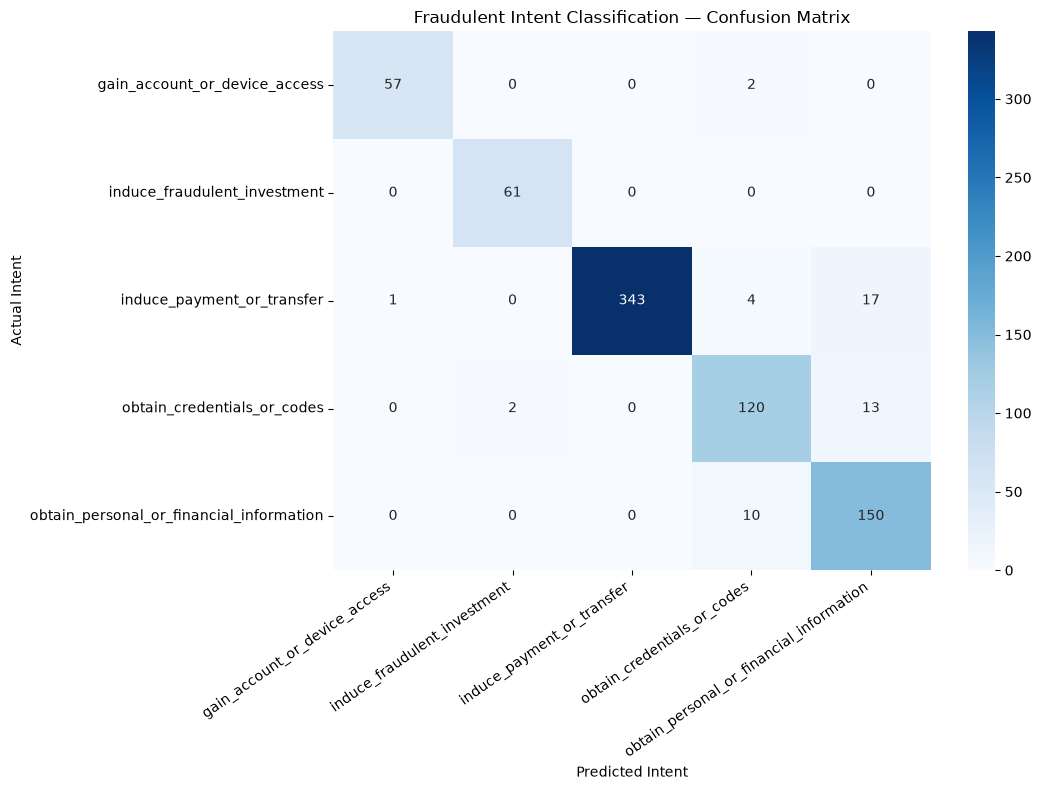

In [23]:
# Intent confusion matrix

import matplotlib.pyplot as plt
import seaborn as sns

intent_labels = sorted(y_intent.unique())

intent_cm = confusion_matrix(
    y_intent_val,
    y_intent_pred,
    labels=intent_labels
)

plt.figure(figsize=(11, 8))
sns.heatmap(
    intent_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=intent_labels,
    yticklabels=intent_labels
)

plt.title("Fraudulent Intent Classification — Confusion Matrix")
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [24]:
# Inspect misclassified intent narratives

intent_errors = pd.DataFrame({
    "actual": y_intent_val,
    "predicted": y_intent_pred,
    "text": X_val_text
})

intent_errors = intent_errors[
    intent_errors["actual"] != intent_errors["predicted"]
].copy()

print("Total misclassifications:", len(intent_errors))

display(
    pd.crosstab(
        intent_errors["actual"],
        intent_errors["predicted"]
    )
)

for idx, row in intent_errors.head(15).iterrows():
    print("\n" + "=" * 85)
    print("Record:", df.loc[idx, "record_id"])
    print("Actual intent:", row["actual"])
    print("Predicted intent:", row["predicted"])
    print("Text:", row["text"])

Total misclassifications: 49


predicted,gain_account_or_device_access,induce_fraudulent_investment,obtain_credentials_or_codes,obtain_personal_or_financial_information
actual,,,,
gain_account_or_device_access,0,0,2,0
induce_payment_or_transfer,1,0,4,17
obtain_credentials_or_codes,0,2,0,13
obtain_personal_or_financial_information,0,0,10,0



Record: SYN3C-00489
Actual intent: obtain_personal_or_financial_information
Predicted intent: obtain_credentials_or_codes
Text: 🚨 [Summit Federal Credit Union Alert] Foreign network connection detected from overseas IP in Atlanta, GA. Block access at [URL]

Record: SYN3C-00498
Actual intent: obtain_personal_or_financial_information
Predicted intent: obtain_credentials_or_codes
Text: 🚨 [Vanguard Bancorp Alert] Foreign network connection detected from overseas IP in Miami, FL. Block access at [URL]

Record: SYN3C-00500
Actual intent: obtain_personal_or_financial_information
Predicted intent: obtain_credentials_or_codes
Text: 🚨 [First Crest Bank Alert] Foreign network connection detected from overseas IP in Phoenix, AZ. Block access at [URL]

Record: SYN3C-00504
Actual intent: obtain_personal_or_financial_information
Predicted intent: obtain_credentials_or_codes
Text: 🚨 [Pinnacle Bank Alert] Foreign network connection detected from overseas IP in Miami, FL. Block access at [URL]

Record:

In [25]:
# Find identical narratives with conflicting intent labels

narrative_intent_counts = (
    df.groupby("normalized_text")["fraudulent_intent"]
    .nunique()
)

conflicting_narratives = narrative_intent_counts[
    narrative_intent_counts > 1
]

print("Unique narratives:", df["normalized_text"].nunique())
print("Narratives with conflicting intent labels:", len(conflicting_narratives))

conflict_details = (
    df[df["normalized_text"].isin(conflicting_narratives.index)]
    .groupby(["normalized_text", "fraudulent_intent"])
    .size()
    .reset_index(name="count")
    .sort_values(["normalized_text", "fraudulent_intent"])
)

display(conflict_details.head(30))

Unique narratives: 7400
Narratives with conflicting intent labels: 129


,normalized_text,fraudulent_intent,count
0,🔔 [Apex ID Services Notice] Airfare cancellati...,induce_payment_or_transfer,3
1,🔔 [Apex ID Services Notice] Airfare cancellati...,obtain_personal_or_financial_information,1
2,🔔 [Apex ID Services Notice] Commercial freight...,induce_payment_or_transfer,1
3,🔔 [Apex ID Services Notice] Commercial freight...,obtain_personal_or_financial_information,1
4,🔔 [Apex ID Services Notice] Part-time e-commer...,induce_payment_or_transfer,3
5,🔔 [Apex ID Services Notice] Part-time e-commer...,obtain_personal_or_financial_information,1
6,🔔 [Apex ID Services Notice] Prorated enterpris...,gain_account_or_device_access,1
7,🔔 [Apex ID Services Notice] Prorated enterpris...,induce_payment_or_transfer,1
8,🔔 [Apex ID Services Notice] Prorated enterpris...,obtain_personal_or_financial_information,1
9,🔔 [Apex National Bank Alert] Home equity liqui...,obtain_credentials_or_codes,2


In [26]:
# Quantify conflicting narrative labels

conflict_groups = (
    df.groupby("normalized_text")
    .agg(
        record_count=("record_id", "size"),
        intent_count=("fraudulent_intent", "nunique"),
        intents=("fraudulent_intent", lambda x: sorted(x.unique()))
    )
    .query("intent_count > 1")
    .sort_values("record_count", ascending=False)
)

conflicting_record_count = conflict_groups["record_count"].sum()

print("Distinct conflicting narratives:", len(conflict_groups))
print("Records belonging to conflicting narratives:", conflicting_record_count)
print(f"Percentage of dataset: {conflicting_record_count / len(df) * 100:.2f}%")

print("\nConflicting intent combinations:")
display(
    conflict_groups["intents"]
    .value_counts()
    .rename_axis("intent_combination")
    .reset_index(name="narrative_count")
)

print("\nLargest conflicting groups:")
display(conflict_groups.head(20))

Distinct conflicting narratives: 129
Records belonging to conflicting narratives: 438
Percentage of dataset: 5.62%

Conflicting intent combinations:


,intent_combination,narrative_count
0,"[induce_payment_or_transfer, obtain_personal_o...",35
1,"[obtain_credentials_or_codes, obtain_personal_...",31
2,"[induce_payment_or_transfer, obtain_credential...",19
3,"[induce_payment_or_transfer, obtain_credential...",10
4,"[gain_account_or_device_access, induce_payment...",7
5,"[gain_account_or_device_access, induce_payment...",5
6,"[gain_account_or_device_access, obtain_credent...",5
7,"[gain_account_or_device_access, obtain_persona...",5
8,"[gain_account_or_device_access, induce_payment...",3
9,"[gain_account_or_device_access, obtain_credent...",3



Largest conflicting groups:


,record_count,intent_count,intents
normalized_text,,,
🚨 [Tax Revenue Bureau] Commercial franchise tax assessment docket #[IDENTIFIER] ([AMOUNT]) is overdue. Pay assessment at [URL],16,3,"[induce_payment_or_transfer, obtain_credential..."
🚨 [Tax Revenue Bureau] Audit docket #[IDENTIFIER] determined unresolved income tax liability of [AMOUNT]. Settle debt at [URL],16,3,"[induce_payment_or_transfer, obtain_credential..."
🚨 [Tax Revenue Bureau] W-2 withholding payroll discrepancy created unpaid statutory balance of [AMOUNT]. Reconcile file at [URL],15,3,"[induce_payment_or_transfer, obtain_credential..."
🚨 [Tax Revenue Bureau] Formal federal tax lien #[IDENTIFIER] recorded for delinquent taxes of [AMOUNT]. Resolve lien at [URL],13,3,"[induce_payment_or_transfer, obtain_credential..."
🔔 [Restitution Office] Consumer protection audit approved restitution payout of [AMOUNT]. Release funds at [URL],10,3,"[gain_account_or_device_access, induce_payment..."
🚨 [Tax Revenue Bureau] Quarterly tax underpayment assessment file #[IDENTIFIER] totaling [AMOUNT] due. Settle penalty at [URL],10,3,"[induce_payment_or_transfer, obtain_credential..."
🔔 [Restitution Office] Judicial restitution decree #[IDENTIFIER] allocated [AMOUNT] in damages. Claim restitution at [URL],9,3,"[gain_account_or_device_access, induce_payment..."
🚨 [Centennial Mutual Alert] Access placed on hold after three invalid passcode attempts. Unlock profile at [URL],8,3,"[gain_account_or_device_access, obtain_credent..."
🔔 [CloudShield Security Notice] Duplicate overpayment credit of [AMOUNT] deposited to your profile. Review ledger at [URL],7,3,"[gain_account_or_device_access, induce_payment..."


In [27]:
# Check conflicting narratives across dataset partitions

conflict_partition_details = (
    df[df["normalized_text"].isin(conflicting_narratives.index)]
    .groupby(["normalized_text", "split_partition"])
    .agg(
        records=("record_id", "size"),
        intent_count=("fraudulent_intent", "nunique"),
        intents=("fraudulent_intent", lambda x: sorted(x.unique()))
    )
    .reset_index()
)

print("Conflicting narratives by partition:")
display(
    conflict_partition_details.groupby("split_partition").agg(
        narrative_groups=("normalized_text", "nunique"),
        records=("records", "sum"),
        groups_with_internal_conflicts=("intent_count", lambda x: (x > 1).sum())
    )
)

print("\nNarratives appearing in multiple partitions:")
narrative_partition_counts = (
    conflict_partition_details.groupby("normalized_text")["split_partition"]
    .nunique()
)

print(
    "Conflicting narratives spanning multiple partitions:",
    (narrative_partition_counts > 1).sum()
)

print("\nDetailed partition examples:")
display(conflict_partition_details.head(20))

Conflicting narratives by partition:


,narrative_groups,records,groups_with_internal_conflicts
split_partition,,,
test,16,46,16
train,98,348,98
val,15,44,15



Narratives appearing in multiple partitions:
Conflicting narratives spanning multiple partitions: 0

Detailed partition examples:


,normalized_text,split_partition,records,intent_count,intents
0,🔔 [Apex ID Services Notice] Airfare cancellati...,train,4,2,"[induce_payment_or_transfer, obtain_personal_o..."
1,🔔 [Apex ID Services Notice] Commercial freight...,test,2,2,"[induce_payment_or_transfer, obtain_personal_o..."
2,🔔 [Apex ID Services Notice] Part-time e-commer...,test,4,2,"[induce_payment_or_transfer, obtain_personal_o..."
3,🔔 [Apex ID Services Notice] Prorated enterpris...,test,3,3,"[gain_account_or_device_access, induce_payment..."
4,🔔 [Apex National Bank Alert] Home equity liqui...,train,3,2,"[obtain_credentials_or_codes, obtain_personal_..."
5,🔔 [AppleCash Express Alert] Digital scratch-of...,train,2,2,"[induce_payment_or_transfer, obtain_personal_o..."
6,🔔 [AppleCash Express Alert] Official grant sta...,train,2,2,"[induce_payment_or_transfer, obtain_personal_o..."
7,🔔 [AppleCash Express Alert] Selected for execu...,train,5,2,"[induce_payment_or_transfer, obtain_personal_o..."
8,🔔 [AppleCash Express Alert] Unclaimed complete...,train,3,2,"[induce_payment_or_transfer, obtain_personal_o..."
9,🔔 [AuthGuardian Inc. Notice] Airfare cancellat...,train,5,3,"[gain_account_or_device_access, induce_payment..."


In [28]:
# Inspect intent evidence for conflicting narratives

conflict_evidence = (
    df[df["normalized_text"].isin(conflicting_narratives.index)]
    .groupby(["normalized_text", "fraudulent_intent"])
    .agg(
        records=("record_id", "size"),
        evidence_values=("primary_intent_evidence", "nunique"),
        evidence_samples=(
            "primary_intent_evidence",
            lambda x: list(x.unique())[:3]
        ),
        scenario_families=("scenario_family", "nunique")
    )
    .reset_index()
)

print("Conflicting narrative-label combinations:", len(conflict_evidence))

display(conflict_evidence.head(25))

Conflicting narrative-label combinations: 281


,normalized_text,fraudulent_intent,records,evidence_values,evidence_samples,scenario_families
0,🔔 [Apex ID Services Notice] Airfare cancellati...,induce_payment_or_transfer,3,1,"[{""start_char"": 98, ""end_char"": 152, ""span_tex...",1
1,🔔 [Apex ID Services Notice] Airfare cancellati...,obtain_personal_or_financial_information,1,1,"[{""start_char"": 96, ""end_char"": 150, ""span_tex...",1
2,🔔 [Apex ID Services Notice] Commercial freight...,induce_payment_or_transfer,1,1,"[{""start_char"": 105, ""end_char"": 160, ""span_te...",1
3,🔔 [Apex ID Services Notice] Commercial freight...,obtain_personal_or_financial_information,1,1,"[{""start_char"": 107, ""end_char"": 162, ""span_te...",1
4,🔔 [Apex ID Services Notice] Part-time e-commer...,induce_payment_or_transfer,3,1,"[{""start_char"": 108, ""end_char"": 160, ""span_te...",1
5,🔔 [Apex ID Services Notice] Part-time e-commer...,obtain_personal_or_financial_information,1,1,"[{""start_char"": 108, ""end_char"": 160, ""span_te...",1
6,🔔 [Apex ID Services Notice] Prorated enterpris...,gain_account_or_device_access,1,1,"[{""start_char"": 91, ""end_char"": 146, ""span_tex...",1
7,🔔 [Apex ID Services Notice] Prorated enterpris...,induce_payment_or_transfer,1,1,"[{""start_char"": 93, ""end_char"": 148, ""span_tex...",1
8,🔔 [Apex ID Services Notice] Prorated enterpris...,obtain_personal_or_financial_information,1,1,"[{""start_char"": 93, ""end_char"": 148, ""span_tex...",1
9,🔔 [Apex National Bank Alert] Home equity liqui...,obtain_credentials_or_codes,2,1,"[{""start_char"": 95, ""end_char"": 148, ""span_tex...",1


In [29]:
# Inspect evidence spans for representative conflicting narratives

representative_texts = conflict_groups.head(5).index.tolist()

for narrative in representative_texts:
    print("\n" + "=" * 100)
    print("NARRATIVE:")
    print(narrative)

    examples = df[df["normalized_text"] == narrative][
        ["record_id", "fraudulent_intent", "primary_intent_evidence"]
    ]

    display(examples)


NARRATIVE:
🚨 [Tax Revenue Bureau] Commercial franchise tax assessment docket #[IDENTIFIER] ([AMOUNT]) is overdue. Pay assessment at [URL]


,record_id,fraudulent_intent,primary_intent_evidence
4527,SYN3C-04528,induce_payment_or_transfer,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."
4528,SYN3C-04529,induce_payment_or_transfer,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."
4530,SYN3C-04531,obtain_personal_or_financial_information,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."
4533,SYN3C-04534,induce_payment_or_transfer,"{""start_char"": 98, ""end_char"": 161, ""span_text..."
4535,SYN3C-04536,induce_payment_or_transfer,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."
4536,SYN3C-04537,obtain_credentials_or_codes,"{""start_char"": 98, ""end_char"": 161, ""span_text..."
4542,SYN3C-04543,induce_payment_or_transfer,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."
4545,SYN3C-04546,obtain_personal_or_financial_information,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."
4546,SYN3C-04547,induce_payment_or_transfer,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."
4547,SYN3C-04548,induce_payment_or_transfer,"{""start_char"": 100, ""end_char"": 163, ""span_tex..."



NARRATIVE:
🚨 [Tax Revenue Bureau] Audit docket #[IDENTIFIER] determined unresolved income tax liability of [AMOUNT]. Settle debt at [URL]


,record_id,fraudulent_intent,primary_intent_evidence
4202,SYN3C-04203,obtain_credentials_or_codes,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."
4206,SYN3C-04207,obtain_personal_or_financial_information,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."
4208,SYN3C-04209,induce_payment_or_transfer,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."
4211,SYN3C-04212,induce_payment_or_transfer,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."
4215,SYN3C-04216,induce_payment_or_transfer,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."
4216,SYN3C-04217,induce_payment_or_transfer,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."
4226,SYN3C-04227,obtain_credentials_or_codes,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."
4233,SYN3C-04234,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 161, ""span_tex..."
4237,SYN3C-04238,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 161, ""span_tex..."
4238,SYN3C-04239,induce_payment_or_transfer,"{""start_char"": 103, ""end_char"": 163, ""span_tex..."



NARRATIVE:
🚨 [Tax Revenue Bureau] W-2 withholding payroll discrepancy created unpaid statutory balance of [AMOUNT]. Reconcile file at [URL]


,record_id,fraudulent_intent,primary_intent_evidence
4441,SYN3C-04442,induce_payment_or_transfer,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4442,SYN3C-04443,induce_payment_or_transfer,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4450,SYN3C-04451,induce_payment_or_transfer,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4457,SYN3C-04458,obtain_credentials_or_codes,"{""start_char"": 104, ""end_char"": 167, ""span_tex..."
4460,SYN3C-04461,induce_payment_or_transfer,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4474,SYN3C-04475,obtain_personal_or_financial_information,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4476,SYN3C-04477,obtain_personal_or_financial_information,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4481,SYN3C-04482,obtain_personal_or_financial_information,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4491,SYN3C-04492,obtain_personal_or_financial_information,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."
4495,SYN3C-04496,obtain_credentials_or_codes,"{""start_char"": 106, ""end_char"": 169, ""span_tex..."



NARRATIVE:
🚨 [Tax Revenue Bureau] Formal federal tax lien #[IDENTIFIER] recorded for delinquent taxes of [AMOUNT]. Resolve lien at [URL]


,record_id,fraudulent_intent,primary_intent_evidence
4283,SYN3C-04284,obtain_personal_or_financial_information,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4299,SYN3C-04300,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4305,SYN3C-04306,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4308,SYN3C-04309,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4319,SYN3C-04320,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4331,SYN3C-04332,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4333,SYN3C-04334,induce_payment_or_transfer,"{""start_char"": 99, ""end_char"": 160, ""span_text..."
4338,SYN3C-04339,induce_payment_or_transfer,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4343,SYN3C-04344,obtain_credentials_or_codes,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."
4347,SYN3C-04348,obtain_personal_or_financial_information,"{""start_char"": 101, ""end_char"": 162, ""span_tex..."



NARRATIVE:
🔔 [Restitution Office] Consumer protection audit approved restitution payout of [AMOUNT]. Release funds at [URL]


,record_id,fraudulent_intent,primary_intent_evidence
6840,SYN3C-06841,induce_payment_or_transfer,"{""start_char"": 91, ""end_char"": 154, ""span_text..."
6847,SYN3C-06848,gain_account_or_device_access,"{""start_char"": 91, ""end_char"": 154, ""span_text..."
6859,SYN3C-06860,induce_payment_or_transfer,"{""start_char"": 91, ""end_char"": 154, ""span_text..."
6866,SYN3C-06867,gain_account_or_device_access,"{""start_char"": 91, ""end_char"": 154, ""span_text..."
6868,SYN3C-06869,gain_account_or_device_access,"{""start_char"": 91, ""end_char"": 154, ""span_text..."
6890,SYN3C-06891,obtain_credentials_or_codes,"{""start_char"": 89, ""end_char"": 152, ""span_text..."
6897,SYN3C-06898,obtain_credentials_or_codes,"{""start_char"": 89, ""end_char"": 152, ""span_text..."
6910,SYN3C-06911,gain_account_or_device_access,"{""start_char"": 91, ""end_char"": 154, ""span_text..."
6915,SYN3C-06916,gain_account_or_device_access,"{""start_char"": 91, ""end_char"": 154, ""span_text..."
6917,SYN3C-06918,induce_payment_or_transfer,"{""start_char"": 91, ""end_char"": 154, ""span_text..."


In [30]:
# Compare actual evidence span text across conflicting intent labels

representative_texts = conflict_groups.head(3).index.tolist()

for narrative in representative_texts:
    print("\n" + "=" * 100)
    print("NARRATIVE:", narrative)

    examples = df.loc[
        df["normalized_text"] == narrative,
        ["record_id", "fraudulent_intent", "primary_intent_evidence"]
    ].sort_values("fraudulent_intent")

    for _, row in examples.iterrows():
        evidence = row["primary_intent_evidence"]

        if isinstance(evidence, str):
            evidence = json.loads(evidence)

        print(
            f"\n{row['record_id']} | {row['fraudulent_intent']}"
        )

        if isinstance(evidence, dict):
            print("Span:", repr(evidence.get("span_text")))
        elif isinstance(evidence, list):
            print("Spans:", [item.get("span_text") for item in evidence])
        else:
            print("Evidence:", repr(evidence))


NARRATIVE: 🚨 [Tax Revenue Bureau] Commercial franchise tax assessment docket #[IDENTIFIER] ([AMOUNT]) is overdue. Pay assessment at [URL]

SYN3C-04528 | induce_payment_or_transfer
Span: 'Pay assessment at https://portal.tax-compliance.example/verify.'

SYN3C-04529 | induce_payment_or_transfer
Span: 'Pay assessment at https://portal.tax-compliance.example/verify.'

SYN3C-04534 | induce_payment_or_transfer
Span: 'Pay assessment at https://portal.tax-compliance.example/verify.'

SYN3C-04536 | induce_payment_or_transfer
Span: 'Pay assessment at https://portal.tax-compliance.example/verify.'

SYN3C-04543 | induce_payment_or_transfer
Span: 'Pay assessment at https://portal.tax-compliance.example/verify.'

SYN3C-04547 | induce_payment_or_transfer
Span: 'Pay assessment at https://portal.tax-compliance.example/verify.'

SYN3C-04548 | induce_payment_or_transfer
Span: 'Pay assessment at https://portal.tax-compliance.example/verify.'

SYN3C-04551 | induce_payment_or_transfer
Span: 'Pay assessment

In [31]:
# dataset v3.1

V31_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "synthetic_financial_scams_v3_1_processed.csv"

df_v31 = pd.read_csv(V31_DATA_PATH)

print("Dataset shape:", df_v31.shape)
print("\nChannel distribution:")
display(df_v31["channel"].value_counts())

print("\nIntent distribution:")
display(df_v31["fraudulent_intent"].value_counts())

print("\nPartition distribution:")
display(df_v31["split_partition"].value_counts())

Dataset shape: (7800, 36)

Channel distribution:


channel
email           2687
sms             2535
chat            1771
notification     807
Name: count, dtype: int64


Intent distribution:


fraudulent_intent
induce_payment_or_transfer                  3684
obtain_personal_or_financial_information    1792
obtain_credentials_or_codes                 1160
gain_account_or_device_access                582
induce_fraudulent_investment                 582
Name: count, dtype: int64


Partition distribution:


split_partition
train    6240
val       780
test      780
Name: count, dtype: int64

In [32]:
# Inspect the distribution of fraudulent intent labels within notification records

notification_df = df_v31[df_v31["channel"] == "notification"].copy()

print("Notification records:", len(notification_df))
print("\nIntent distribution within notifications:")

display(
    notification_df["fraudulent_intent"]
    .value_counts()
    .rename_axis("fraudulent_intent")
    .to_frame("count")
    .assign(
        percentage=lambda x: (
            x["count"] / len(notification_df) * 100
        ).round(2)
    )
)

Notification records: 807

Intent distribution within notifications:


,count,percentage
fraudulent_intent,,
induce_payment_or_transfer,254,31.47
obtain_personal_or_financial_information,249,30.86
obtain_credentials_or_codes,209,25.90
gain_account_or_device_access,57,7.06
induce_fraudulent_investment,38,4.71


In [33]:
# Display representative training notifications for qualitative intent verification

notification_samples = (
    notification_df[notification_df["split_partition"] == "train"]
    .groupby("fraudulent_intent", group_keys=False)
    .sample(n=3, random_state=42)
)

for intent, group in notification_samples.groupby("fraudulent_intent"):
    print("\n" + "=" * 100)
    print("INTENT:", intent)

    for _, row in group.iterrows():
        print(f"\nRecord: {row['record_id']}")
        print("Message:", row["original_text"])
        print("Evidence:", row["primary_intent_evidence"])


INTENT: gain_account_or_device_access

Record: SYN31-01487
Message: 🏨 [GrandResort Desk] Hotel notice: Reservation incidental deposit refund of $3,229.50 is ready. Download guest concierge utility from https://support.resort-stay.example/agent.
Evidence: {"start_char": 96, "end_char": 176, "span_text": "Download guest concierge utility from https://support.resort-stay.example/agent."}

Record: SYN31-05255
Message: 🌐 [GlobalTranslation Desk] Careers alert: Professional document translation role #CF-12683 ($1,449.50) open. Translation workspace setup frozen awaiting remote memory daemon connection.
Evidence: {"start_char": 109, "end_char": 185, "span_text": "Translation workspace setup frozen awaiting remote memory daemon connection."}

Record: SYN31-01473
Message: 🔔 [Hospitality Billing] Hotel notice: Reservation incidental deposit refund of $2,008.80 is ready. Rebate disbursement on hold awaiting remote concierge tool connection.
Evidence: {"start_char": 99, "end_char": 169, "span_tex

In [34]:
# Inspect additional training examples from the two potentially ambiguous intent classes

ambiguous_intents = [
    "gain_account_or_device_access",
    "obtain_credentials_or_codes"
]

for intent in ambiguous_intents:
    print("\n" + "=" * 100)
    print("INTENT:", intent)

    samples = (
        df_v31[
            (df_v31["fraudulent_intent"] == intent) &
            (df_v31["split_partition"] == "train")
        ]
        .sample(n=8, random_state=101)
    )

    for _, row in samples.iterrows():
        print(f"\nRecord: {row['record_id']} | Channel: {row['channel']}")
        print("Subtype:", row["scam_subtype"])
        print("Message:", row["original_text"])
        print("Evidence:", row["primary_intent_evidence"])


INTENT: gain_account_or_device_access

Record: SYN31-01505 | Channel: email
Subtype: refund_chargeback
Message: Subject: Settlement Notice: Reimbursement Credit Ready (#CF-90114)

Dear Valued Customer,

Hospitality Settlement: Your security deposit rebate of $4,563.80 is awaiting disbursement approval.

Receive an additional $150 goodwill voucher credited alongside your refund.

Act within 2 hours to avoid forfeiture of unclaimed credit.

Install TeamViewer QuickSupport so our billing representative can connect to your desktop and process your refund voucher directly.

Sincerely,
Billing & Restitution Services
NetDefender Support
Evidence: {"start_char": 331, "end_char": 462, "span_text": "Install TeamViewer QuickSupport so our billing representative can connect to your desktop and process your refund voucher directly."}

Record: SYN31-04956 | Channel: chat
Subtype: job_task_commission
Message: [18:50 PM] Talent_Coordinator_Alex: Remote Media Role: Digital video compliance reviewer wa

In [35]:
# Prepare V3.1 intent targets and training-validation text data

y_intent_v31 = df_v31["fraudulent_intent"]

train_idx_v31 = df_v31.index[df_v31["split_partition"] == "train"]
val_idx_v31 = df_v31.index[df_v31["split_partition"] == "val"]

X_train_text_v31 = df_v31.loc[train_idx_v31, "normalized_text"]
X_val_text_v31 = df_v31.loc[val_idx_v31, "normalized_text"]

y_intent_train_v31 = y_intent_v31.loc[train_idx_v31]
y_intent_val_v31 = y_intent_v31.loc[val_idx_v31]

print("Training samples:", len(X_train_text_v31))
print("Validation samples:", len(X_val_text_v31))
print("\nTraining intent distribution:")
display(y_intent_train_v31.value_counts())

print("\nValidation intent distribution:")
display(y_intent_val_v31.value_counts())

Training samples: 6240
Validation samples: 780

Training intent distribution:


fraudulent_intent
induce_payment_or_transfer                  2924
obtain_personal_or_financial_information    1469
obtain_credentials_or_codes                  906
gain_account_or_device_access                478
induce_fraudulent_investment                 463
Name: count, dtype: int64


Validation intent distribution:


fraudulent_intent
induce_payment_or_transfer                  388
obtain_personal_or_financial_information    158
obtain_credentials_or_codes                 126
induce_fraudulent_investment                 64
gain_account_or_device_access                44
Name: count, dtype: int64

In [36]:
# Build TF-IDF features for V3.1 using the same configuration as the V3 baseline

tfidf_v31 = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    dtype=np.float32
)

X_train_tfidf_v31 = tfidf_v31.fit_transform(X_train_text_v31)
X_val_tfidf_v31 = tfidf_v31.transform(X_val_text_v31)

print("Training feature shape:", X_train_tfidf_v31.shape)
print("Validation feature shape:", X_val_tfidf_v31.shape)
print("Vocabulary size:", len(tfidf_v31.vocabulary_))
print("Training non-zero values:", X_train_tfidf_v31.nnz)
print("Training matrix memory:", round(
    (X_train_tfidf_v31.data.nbytes +
     X_train_tfidf_v31.indices.nbytes +
     X_train_tfidf_v31.indptr.nbytes) / (1024 ** 2), 2
), "MB")

Training feature shape: (6240, 13252)
Validation feature shape: (780, 13252)
Vocabulary size: 13252
Training non-zero values: 627406
Training matrix memory: 4.81 MB


In [37]:
# Train the V3.1 Logistic Regression baseline for fraudulent intent classification

intent_model_v31 = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=2000,
    random_state=RANDOM_STATE
)

intent_model_v31.fit(X_train_tfidf_v31, y_intent_train_v31)

y_intent_pred_v31 = intent_model_v31.predict(X_val_tfidf_v31)

print("V3.1 intent model training completed.")

V3.1 intent model training completed.


In [38]:
# Evaluate the V3.1 intent classifier on the validation set

print("V3.1 Intent Classification Results\n")

print("Accuracy:", round(accuracy_score(y_intent_val_v31, y_intent_pred_v31), 4))
print("Macro F1:", round(f1_score(y_intent_val_v31, y_intent_pred_v31, average="macro"), 4))
print("Weighted F1:", round(f1_score(y_intent_val_v31, y_intent_pred_v31, average="weighted"), 4))

print("\nClassification Report:")
print(classification_report(y_intent_val_v31, y_intent_pred_v31, digits=4))

V3.1 Intent Classification Results

Accuracy: 0.9821
Macro F1: 0.9816
Weighted F1: 0.9821

Classification Report:
                                          precision    recall  f1-score   support

           gain_account_or_device_access     1.0000    1.0000    1.0000        44
            induce_fraudulent_investment     1.0000    1.0000    1.0000        64
              induce_payment_or_transfer     1.0000    0.9923    0.9961       388
             obtain_credentials_or_codes     0.9915    0.9206    0.9547       126
obtain_personal_or_financial_information     0.9235    0.9937    0.9573       158

                                accuracy                         0.9821       780
                               macro avg     0.9830    0.9813    0.9816       780
                            weighted avg     0.9831    0.9821    0.9821       780



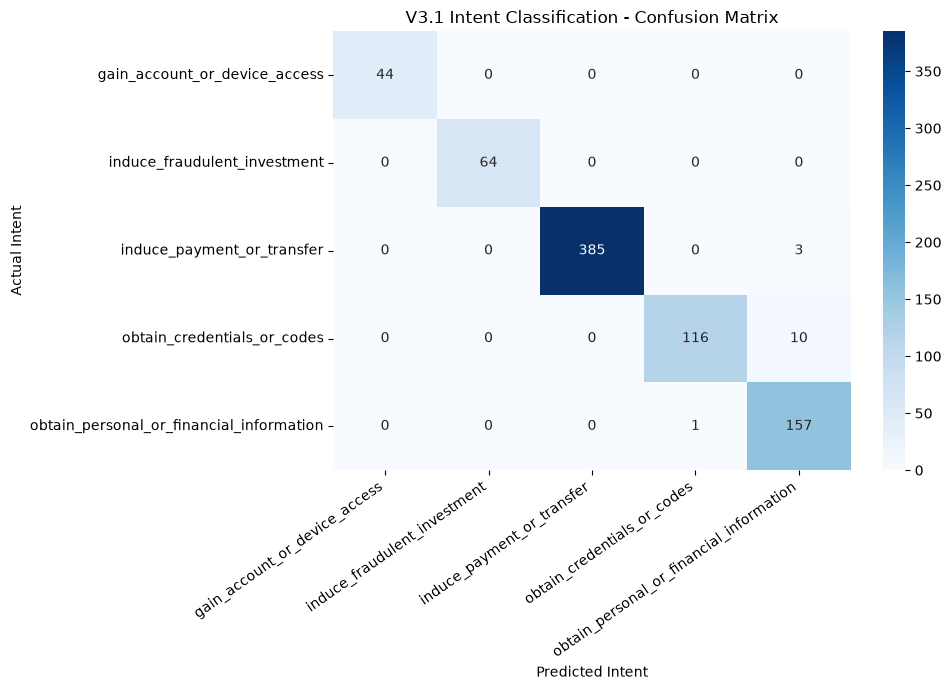

In [39]:
# Visualize the V3.1 intent classification confusion matrix

cm_intent_v31 = confusion_matrix(
    y_intent_val_v31,
    y_intent_pred_v31,
    labels=intent_model_v31.classes_
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm_intent_v31,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=intent_model_v31.classes_,
    yticklabels=intent_model_v31.classes_
)

plt.title("V3.1 Intent Classification - Confusion Matrix")
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [40]:
# Inspect misclassified validation examples to understand intent-class confusion

misclassified_intent_v31 = pd.DataFrame({
    "text": X_val_text_v31,
    "actual_intent": y_intent_val_v31,
    "predicted_intent": y_intent_pred_v31
})

misclassified_intent_v31 = misclassified_intent_v31[
    misclassified_intent_v31["actual_intent"] !=
    misclassified_intent_v31["predicted_intent"]
]

print("Total misclassifications:", len(misclassified_intent_v31))

for _, row in misclassified_intent_v31.iterrows():
    print("\n" + "-" * 100)
    print("ACTUAL:   ", row["actual_intent"])
    print("PREDICTED:", row["predicted_intent"])
    print("TEXT:", row["text"])

Total misclassifications: 14

----------------------------------------------------------------------------------------------------
ACTUAL:    obtain_personal_or_financial_information
PREDICTED: obtain_credentials_or_codes
TEXT: 🚨 [Centennial Mutual Security] Fraud notice: Cross-border IP address attempted portal connection. Account security restriction active pending cardholder KYC confirmation.

----------------------------------------------------------------------------------------------------
ACTUAL:    induce_payment_or_transfer
PREDICTED: obtain_personal_or_financial_information
TEXT: 🚨 [Pinnacle Bank Security] Replacement debit card shipment reroute request received. Open ZelleConnect to pay certified card re-issuance fee of [AMOUNT].

----------------------------------------------------------------------------------------------------
ACTUAL:    obtain_credentials_or_codes
PREDICTED: obtain_personal_or_financial_information
TEXT: 🚨 [Summit Federal Credit Union Security] Card secu

In [41]:
# Create manually paraphrased messages to test robustness to lexical variation

robustness_samples = [
    # Payment or transfer
    ("induce_payment_or_transfer",
     "Send the outstanding amount to the designated settlement account to release your funds."),
    ("induce_payment_or_transfer",
     "A processing charge remains unpaid. Complete the deposit before your claim expires."),
    ("induce_payment_or_transfer",
     "Transfer the required security fee to finalize the refund authorization."),

    # Personal or financial information
    ("obtain_personal_or_financial_information",
     "Confirm your identity by providing your national identification number and billing details."),
    ("obtain_personal_or_financial_information",
     "We require your bank account number and card details to complete the verification."),
    ("obtain_personal_or_financial_information",
     "Submit your date of birth and registered payment information to validate your profile."),

    # Credentials or codes
    ("obtain_credentials_or_codes",
     "Enter the secret phrase associated with your online banking profile."),
    ("obtain_credentials_or_codes",
     "Provide the temporary authentication number sent to your registered phone."),
    ("obtain_credentials_or_codes",
     "Sign in using your account password to prevent the pending restriction."),

    # Account or device access
    ("gain_account_or_device_access",
     "Allow our support technician to remotely control your computer to resolve the account issue."),
    ("gain_account_or_device_access",
     "Install the remote assistance application and grant the representative a device session."),
    ("gain_account_or_device_access",
     "Enable remote administration so the recovery team can access your workstation."),

    # Fraudulent investment
    ("induce_fraudulent_investment",
     "Commit funds to the proposed digital asset pool to receive the advertised daily returns."),
    ("induce_fraudulent_investment",
     "Purchase a share in the automated cryptocurrency trading program to unlock projected profits."),
    ("induce_fraudulent_investment",
     "Deposit capital into the mining contract to participate in its promised yield distribution.")
]

robustness_df = pd.DataFrame(
    robustness_samples,
    columns=["actual_intent", "text"]
)

print("Challenge examples:", len(robustness_df))
display(robustness_df)

Challenge examples: 15


,actual_intent,text
0,induce_payment_or_transfer,Send the outstanding amount to the designated ...
1,induce_payment_or_transfer,A processing charge remains unpaid. Complete t...
2,induce_payment_or_transfer,Transfer the required security fee to finalize...
3,obtain_personal_or_financial_information,Confirm your identity by providing your nation...
4,obtain_personal_or_financial_information,We require your bank account number and card d...
5,obtain_personal_or_financial_information,Submit your date of birth and registered payme...
6,obtain_credentials_or_codes,Enter the secret phrase associated with your o...
7,obtain_credentials_or_codes,Provide the temporary authentication number se...
8,obtain_credentials_or_codes,Sign in using your account password to prevent...
9,gain_account_or_device_access,Allow our support technician to remotely contr...


In [42]:
# Evaluate the trained V3.1 intent model on manually paraphrased messages

X_robustness = tfidf_v31.transform(robustness_df["text"])

robustness_predictions = intent_model_v31.predict(X_robustness)
robustness_probabilities = intent_model_v31.predict_proba(X_robustness)

robustness_df["predicted_intent"] = robustness_predictions
robustness_df["confidence"] = robustness_probabilities.max(axis=1)
robustness_df["correct"] = (
    robustness_df["actual_intent"] == robustness_df["predicted_intent"]
)

display(
    robustness_df[
        ["actual_intent", "predicted_intent", "confidence", "correct", "text"]
    ]
)

print("\nExploratory Robustness Accuracy:",
      round(robustness_df["correct"].mean(), 4))

print("Correct predictions:",
      robustness_df["correct"].sum(), "/", len(robustness_df))

,actual_intent,predicted_intent,confidence,correct,text
0,induce_payment_or_transfer,induce_payment_or_transfer,0.951917,True,Send the outstanding amount to the designated ...
1,induce_payment_or_transfer,induce_payment_or_transfer,0.337352,True,A processing charge remains unpaid. Complete t...
2,induce_payment_or_transfer,induce_payment_or_transfer,0.604545,True,Transfer the required security fee to finalize...
3,obtain_personal_or_financial_information,obtain_personal_or_financial_information,0.992494,True,Confirm your identity by providing your nation...
4,obtain_personal_or_financial_information,obtain_personal_or_financial_information,0.988258,True,We require your bank account number and card d...
5,obtain_personal_or_financial_information,obtain_personal_or_financial_information,0.938412,True,Submit your date of birth and registered payme...
6,obtain_credentials_or_codes,obtain_credentials_or_codes,0.946597,True,Enter the secret phrase associated with your o...
7,obtain_credentials_or_codes,obtain_credentials_or_codes,0.516914,True,Provide the temporary authentication number se...
8,obtain_credentials_or_codes,obtain_credentials_or_codes,0.877708,True,Sign in using your account password to prevent...
9,gain_account_or_device_access,gain_account_or_device_access,0.429741,True,Allow our support technician to remotely contr...



Exploratory Robustness Accuracy: 0.8667
Correct predictions: 13 / 15


In [43]:
# Compare the strongest TF-IDF features associated with payment and investment predictions

feature_names = tfidf_v31.get_feature_names_out()

for label in ["induce_payment_or_transfer", "induce_fraudulent_investment"]:
    class_index = np.where(intent_model_v31.classes_ == label)[0][0]
    coefficients = intent_model_v31.coef_[class_index]

    top_indices = np.argsort(coefficients)[-25:][::-1]

    print(f"\nTop features for: {label}")
    print("-" * 65)

    for index in top_indices:
        print(f"{feature_names[index]:35s} {coefficients[index]:.4f}")


Top features for: induce_payment_or_transfer
-----------------------------------------------------------------
through                             3.0287
via                                 3.0206
amount                              2.8983
remit                               2.6458
fee                                 2.5452
wire                                2.4110
transfer                            2.2638
amount through                      2.1951
of amount                           2.1171
amount via                          1.8963
of                                  1.8272
wire transfer                       1.7674
to release                          1.7235
fee of                              1.7221
please                              1.6301
to our                              1.5548
you please                          1.5336
release                             1.4998
refundable                          1.4865
via wire                            1.4338
amount to                   

In [44]:
# Inspect features that push predictions away from payment and investment classes

for label in ["induce_payment_or_transfer", "induce_fraudulent_investment"]:
    class_index = np.where(intent_model_v31.classes_ == label)[0][0]
    coefficients = intent_model_v31.coef_[class_index]

    bottom_indices = np.argsort(coefficients)[:25]

    print(f"\nFeatures least associated with: {label}")
    print("-" * 65)

    for index in bottom_indices:
        print(f"{feature_names[index]:35s} {coefficients[index]:.4f}")


Features least associated with: induce_payment_or_transfer
-----------------------------------------------------------------
url                                 -2.8376
at url                              -2.4420
url to                              -2.3447
your                                -2.1282
at                                  -1.7660
card                                -1.7587
into                                -1.3732
install                             -1.3510
launch                              -1.3499
submit your                         -1.2654
enter                               -1.2599
banking                             -1.2595
remote                              -1.2565
so our                              -1.2550
app to                              -1.2114
credentials                         -1.1943
passcode                            -1.1766
number                              -1.1520
details                             -1.1394
profile                             -1

In [45]:
# Create controlled lexical-ablation versions of the investment challenge messages

investment_terms = [
    "trading", "liquidity", "yield",
    "staking", "profits", "capital"
]

investment_mask = (
    robustness_df["actual_intent"] == "induce_fraudulent_investment"
)

ablation_df = robustness_df.loc[investment_mask].copy()

for term in investment_terms:
    ablation_df["text"] = ablation_df["text"].str.replace(
        rf"\b{term}\b", "", regex=True, case=False
    )

ablation_df["text"] = (
    ablation_df["text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

display(ablation_df[["actual_intent", "text"]])

,actual_intent,text
12,induce_fraudulent_investment,Commit funds to the proposed digital asset poo...
13,induce_fraudulent_investment,Purchase a share in the automated cryptocurren...
14,induce_fraudulent_investment,Deposit into the mining contract to participat...


In [46]:
# Display complete ablation messages without dataframe truncation

for index, row in ablation_df.iterrows():
    print(f"\nExample {index}")
    print(f"Actual intent: {row['actual_intent']}")
    print(f"Modified text: {row['text']}")
    print("-" * 80)


Example 12
Actual intent: induce_fraudulent_investment
Modified text: Commit funds to the proposed digital asset pool to receive the advertised daily returns.
--------------------------------------------------------------------------------

Example 13
Actual intent: induce_fraudulent_investment
Modified text: Purchase a share in the automated cryptocurrency program to unlock projected .
--------------------------------------------------------------------------------

Example 14
Actual intent: induce_fraudulent_investment
Modified text: Deposit into the mining contract to participate in its promised distribution.
--------------------------------------------------------------------------------


In [47]:
# Evaluate investment intent predictions after removing selected lexical features

X_ablation = tfidf_v31.transform(ablation_df["text"])

ablation_df["ablation_prediction"] = intent_model_v31.predict(X_ablation)
ablation_df["ablation_confidence"] = intent_model_v31.predict_proba(
    X_ablation
).max(axis=1)

comparison = robustness_df.loc[
    investment_mask, ["actual_intent", "text", "predicted_intent", "confidence"]
].copy()

comparison = comparison.rename(columns={
    "text": "original_text",
    "predicted_intent": "original_prediction",
    "confidence": "original_confidence"
})

comparison["ablated_text"] = ablation_df["text"].values
comparison["ablation_prediction"] = ablation_df["ablation_prediction"].values
comparison["ablation_confidence"] = ablation_df["ablation_confidence"].values

display(comparison)

,actual_intent,original_text,original_prediction,original_confidence,ablated_text,ablation_prediction,ablation_confidence
12,induce_fraudulent_investment,Commit funds to the proposed digital asset poo...,induce_payment_or_transfer,0.480806,Commit funds to the proposed digital asset poo...,induce_payment_or_transfer,0.480806
13,induce_fraudulent_investment,Purchase a share in the automated cryptocurren...,induce_payment_or_transfer,0.322017,Purchase a share in the automated cryptocurren...,induce_payment_or_transfer,0.432386
14,induce_fraudulent_investment,Deposit capital into the mining contract to pa...,induce_fraudulent_investment,0.823998,Deposit into the mining contract to participat...,induce_fraudulent_investment,0.683969


In [48]:
# Inspect social-engineering tactic annotation coverage in V3.1

tactic_coverage = df_v31.groupby("channel").agg(
    total_records=("record_id", "count"),
    annotated_records=(
        "social_engineering_tactics",
        lambda x: x.notna().sum() - (x == "[]").sum()
    )
)

tactic_coverage["unannotated_records"] = (
    tactic_coverage["total_records"] -
    tactic_coverage["annotated_records"]
)

tactic_coverage["annotation_rate"] = (
    tactic_coverage["annotated_records"] /
    tactic_coverage["total_records"] * 100
)

display(tactic_coverage.round(2))

,total_records,annotated_records,unannotated_records,annotation_rate
channel,,,,
chat,1771,1639,132,92.55
email,2687,2483,204,92.41
notification,807,0,807,0.00
sms,2535,2328,207,91.83


In [49]:
# Parse annotated tactic labels and calculate their frequency

import ast
from collections import Counter

annotated_tactics_df = df_v31[
    df_v31["social_engineering_tactics"].notna() &
    (df_v31["social_engineering_tactics"] != "[]")
].copy()

annotated_tactics_df["tactic_list"] = (
    annotated_tactics_df["social_engineering_tactics"]
    .apply(ast.literal_eval)
)

tactic_counts = Counter(
    tactic
    for tactics in annotated_tactics_df["tactic_list"]
    for tactic in tactics
)

tactic_distribution = pd.DataFrame(
    tactic_counts.items(),
    columns=["tactic", "positive_records"]
).sort_values("positive_records", ascending=False)

tactic_distribution["positive_rate"] = (
    tactic_distribution["positive_records"] /
    len(annotated_tactics_df) * 100
)

print(f"Annotated records: {len(annotated_tactics_df):,}")
print(f"Unique tactics: {len(tactic_distribution)}")

display(tactic_distribution.round(2))

Annotated records: 6,450
Unique tactics: 9


,tactic,positive_records,positive_rate
3,urgency,2381,36.91
2,false_legitimacy,1876,29.09
5,reward_or_benefit,1144,17.74
1,authority_impersonation,1038,16.09
7,trust_exploitation,915,14.19
0,secrecy,846,13.12
6,scarcity,747,11.58
8,emotional_manipulation,713,11.05
4,fear_or_threat,630,9.77


In [50]:
# Analyze how many social-engineering tactics are assigned to each message

annotated_tactics_df["tactic_count"] = (
    annotated_tactics_df["tactic_list"].apply(len)
)

tactic_combination_distribution = (
    annotated_tactics_df["tactic_count"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_tactics")
    .reset_index(name="record_count")
)

tactic_combination_distribution["percentage"] = (
    tactic_combination_distribution["record_count"] /
    len(annotated_tactics_df) * 100
)

display(tactic_combination_distribution.round(2))

print(
    f"Average tactics per message: "
    f"{annotated_tactics_df['tactic_count'].mean():.2f}"
)

print(
    f"Maximum tactics in one message: "
    f"{annotated_tactics_df['tactic_count'].max()}"
)

,number_of_tactics,record_count,percentage
0,1,3100,48.06
1,2,2860,44.34
2,3,490,7.60


Average tactics per message: 1.60
Maximum tactics in one message: 3


In [51]:
# Prepare multilabel targets and preserve the existing scenario-family partitions

from sklearn.preprocessing import MultiLabelBinarizer

mlb_v31 = MultiLabelBinarizer()

Y_tactics_v31 = mlb_v31.fit_transform(
    annotated_tactics_df["tactic_list"]
)

tactic_train_mask = (
    annotated_tactics_df["split_partition"] == "train"
)

tactic_val_mask = (
    annotated_tactics_df["split_partition"] == "val"
)

X_tactic_train_text_v31 = annotated_tactics_df.loc[
    tactic_train_mask, "normalized_text"
]

X_tactic_val_text_v31 = annotated_tactics_df.loc[
    tactic_val_mask, "normalized_text"
]

Y_tactic_train_v31 = Y_tactics_v31[tactic_train_mask.values]
Y_tactic_val_v31 = Y_tactics_v31[tactic_val_mask.values]

print("Tactic classes:", list(mlb_v31.classes_))
print("Training records:", len(X_tactic_train_text_v31))
print("Validation records:", len(X_tactic_val_text_v31))
print("Training target shape:", Y_tactic_train_v31.shape)
print("Validation target shape:", Y_tactic_val_v31.shape)

Tactic classes: ['authority_impersonation', 'emotional_manipulation', 'false_legitimacy', 'fear_or_threat', 'reward_or_benefit', 'scarcity', 'secrecy', 'trust_exploitation', 'urgency']
Training records: 5166
Validation records: 645
Training target shape: (5166, 9)
Validation target shape: (645, 9)


In [52]:
# Verify positive examples for every tactic in training and validation partitions

tactic_split_distribution = pd.DataFrame({
    "tactic": mlb_v31.classes_,
    "train_positive": Y_tactic_train_v31.sum(axis=0),
    "validation_positive": Y_tactic_val_v31.sum(axis=0)
})

tactic_split_distribution["train_rate"] = (
    tactic_split_distribution["train_positive"] /
    len(Y_tactic_train_v31) * 100
)

tactic_split_distribution["validation_rate"] = (
    tactic_split_distribution["validation_positive"] /
    len(Y_tactic_val_v31) * 100
)

display(tactic_split_distribution.round(2))

,tactic,train_positive,validation_positive,train_rate,validation_rate
0,authority_impersonation,825,103,15.97,15.97
1,emotional_manipulation,577,64,11.17,9.92
2,false_legitimacy,1517,176,29.37,27.29
3,fear_or_threat,496,71,9.60,11.01
4,reward_or_benefit,893,133,17.29,20.62
5,scarcity,576,94,11.15,14.57
6,secrecy,695,69,13.45,10.70
7,trust_exploitation,743,91,14.38,14.11
8,urgency,1922,245,37.20,37.98


In [53]:
# Train the first TF-IDF and One-vs-Rest Logistic Regression multilabel baseline

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

tfidf_tactics_v31 = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True,
    dtype=np.float32
)

X_tactic_train_tfidf_v31 = tfidf_tactics_v31.fit_transform(
    X_tactic_train_text_v31
)

X_tactic_val_tfidf_v31 = tfidf_tactics_v31.transform(
    X_tactic_val_text_v31
)

tactic_model_v31 = OneVsRestClassifier(
    LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    )
)

tactic_model_v31.fit(
    X_tactic_train_tfidf_v31,
    Y_tactic_train_v31
)

Y_tactic_pred_v31 = tactic_model_v31.predict(
    X_tactic_val_tfidf_v31
)

print("Training feature shape:", X_tactic_train_tfidf_v31.shape)
print("Validation feature shape:", X_tactic_val_tfidf_v31.shape)
print("Vocabulary size:", len(tfidf_tactics_v31.vocabulary_))
print("Model training completed.")

Training feature shape: (5166, 11409)
Validation feature shape: (645, 11409)
Vocabulary size: 11409
Model training completed.


In [54]:
# Evaluate overall multilabel classification performance

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    hamming_loss,
    classification_report
)

print("OVERALL MULTILABEL PERFORMANCE")
print("-" * 55)

print(f"Micro Precision: {precision_score(Y_tactic_val_v31, Y_tactic_pred_v31, average='micro', zero_division=0):.4f}")
print(f"Micro Recall:    {recall_score(Y_tactic_val_v31, Y_tactic_pred_v31, average='micro', zero_division=0):.4f}")
print(f"Micro F1:        {f1_score(Y_tactic_val_v31, Y_tactic_pred_v31, average='micro', zero_division=0):.4f}")
print(f"Macro F1:        {f1_score(Y_tactic_val_v31, Y_tactic_pred_v31, average='macro', zero_division=0):.4f}")
print(f"Weighted F1:     {f1_score(Y_tactic_val_v31, Y_tactic_pred_v31, average='weighted', zero_division=0):.4f}")
print(f"Samples F1:      {f1_score(Y_tactic_val_v31, Y_tactic_pred_v31, average='samples', zero_division=0):.4f}")
print(f"Hamming Loss:    {hamming_loss(Y_tactic_val_v31, Y_tactic_pred_v31):.4f}")

print("\nPER-TACTIC CLASSIFICATION REPORT")
print("-" * 55)

print(classification_report(
    Y_tactic_val_v31,
    Y_tactic_pred_v31,
    target_names=mlb_v31.classes_,
    zero_division=0,
    digits=4
))

OVERALL MULTILABEL PERFORMANCE
-------------------------------------------------------
Micro Precision: 0.9748
Micro Recall:    1.0000
Micro F1:        0.9873
Macro F1:        0.9885
Weighted F1:     0.9875
Samples F1:      0.9867
Hamming Loss:    0.0047

PER-TACTIC CLASSIFICATION REPORT
-------------------------------------------------------
                         precision    recall  f1-score   support

authority_impersonation     1.0000    1.0000    1.0000       103
 emotional_manipulation     0.9275    1.0000    0.9624        64
       false_legitimacy     1.0000    1.0000    1.0000       176
         fear_or_threat     1.0000    1.0000    1.0000        71
      reward_or_benefit     0.9366    1.0000    0.9673       133
               scarcity     1.0000    1.0000    1.0000        94
                secrecy     1.0000    1.0000    1.0000        69
     trust_exploitation     0.9785    1.0000    0.9891        91
                urgency     0.9570    1.0000    0.9780       245

   

In [55]:
# Inspect predicted probability distributions for each social-engineering tactic

Y_tactic_proba_v31 = tactic_model_v31.predict_proba(
    X_tactic_val_tfidf_v31
)

for i, tactic in enumerate(mlb_v31.classes_):
    positive_mask = Y_tactic_val_v31[:, i] == 1
    negative_mask = Y_tactic_val_v31[:, i] == 0

    positive_probs = Y_tactic_proba_v31[positive_mask, i]
    negative_probs = Y_tactic_proba_v31[negative_mask, i]

    print(f"\n{tactic}")
    print(f"  Actual positive mean probability: {positive_probs.mean():.4f}")
    print(f"  Actual negative mean probability: {negative_probs.mean():.4f}")
    print(f"  Minimum positive probability:     {positive_probs.min():.4f}")
    print(f"  Maximum negative probability:     {negative_probs.max():.4f}")


authority_impersonation
  Actual positive mean probability: 0.8947
  Actual negative mean probability: 0.0949
  Minimum positive probability:     0.6455
  Maximum negative probability:     0.4124

emotional_manipulation
  Actual positive mean probability: 0.9410
  Actual negative mean probability: 0.0692
  Minimum positive probability:     0.8623
  Maximum negative probability:     0.6191

false_legitimacy
  Actual positive mean probability: 0.8325
  Actual negative mean probability: 0.1553
  Minimum positive probability:     0.5342
  Maximum negative probability:     0.4982

fear_or_threat
  Actual positive mean probability: 0.9536
  Actual negative mean probability: 0.0631
  Minimum positive probability:     0.8571
  Maximum negative probability:     0.3982

reward_or_benefit
  Actual positive mean probability: 0.9110
  Actual negative mean probability: 0.1253
  Minimum positive probability:     0.6900
  Maximum negative probability:     0.7046

scarcity
  Actual positive mean proba

In [56]:
# Inspect the highest-confidence false positives for each social-engineering tactic

for i, tactic in enumerate(mlb_v31.classes_):
    negative_mask = Y_tactic_val_v31[:, i] == 0

    negative_indices = np.where(negative_mask)[0]
    negative_probabilities = Y_tactic_proba_v31[negative_mask, i]

    top_positions = np.argsort(negative_probabilities)[-3:][::-1]

    print(f"\nTACTIC: {tactic}")
    print("-" * 85)

    for position in top_positions:
        row_index = negative_indices[position]
        probability = negative_probabilities[position]

        if probability >= 0.5:
            print(f"\nProbability: {probability:.4f}")
            print(
                "Actual labels:",
                annotated_tactics_df.loc[
                    annotated_tactics_df["split_partition"] == "val",
                    "tactic_list"
                ].iloc[row_index]
            )
            print(
                "Message:",
                X_tactic_val_text_v31.iloc[row_index]
            )


TACTIC: authority_impersonation
-------------------------------------------------------------------------------------

TACTIC: emotional_manipulation
-------------------------------------------------------------------------------------

Probability: 0.6191
Actual labels: ['trust_exploitation']
Message: [11:42 AM] Alex: Hey Uncle Dave, my vehicle is at the municipal impound lot and I need to pay the release balance before they close. [11:44 AM] Uncle Dave: Wait, is this really you? Why aren't you calling me from your normal number? [11:45 AM] Alex: My phone battery completely died on the road and a good Samaritan let me use their phone to message you. You know that our family bond means everything to me in this difficult moment. Can you please Zelle [AMOUNT] to [EMAIL_ADDRESS] right now so I can get my car back? [11:47 AM] Uncle Dave: Oh god, okay! I'm opening the app right now to send it. Hold on.

Probability: 0.5709
Actual labels: ['trust_exploitation']
Message: [09:41 AM] Kevin: Hi

In [57]:
# Compare multilabel precision and recall across different decision thresholds

from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]:
    predictions = (
        Y_tactic_proba_v31 >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "micro_precision": precision_score(
            Y_tactic_val_v31, predictions,
            average="micro", zero_division=0
        ),
        "micro_recall": recall_score(
            Y_tactic_val_v31, predictions,
            average="micro", zero_division=0
        ),
        "micro_f1": f1_score(
            Y_tactic_val_v31, predictions,
            average="micro", zero_division=0
        ),
        "macro_f1": f1_score(
            Y_tactic_val_v31, predictions,
            average="macro", zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df.round(4))

,threshold,micro_precision,micro_recall,micro_f1,macro_f1
0,0.3,0.7310,1.0000,0.8446,0.8310
1,0.4,0.9096,1.0000,0.9526,0.9531
2,0.5,0.9748,1.0000,0.9873,0.9885
3,0.6,0.9962,0.9924,0.9943,0.9960
4,0.7,0.9990,0.9732,0.9860,0.9901
5,0.8,1.0000,0.8881,0.9408,0.9591
6,0.9,1.0000,0.5793,0.7337,0.7780


In [58]:
# Collect high-confidence false-positive candidates for manual annotation review

audit_tactics = [
    "emotional_manipulation",
    "reward_or_benefit",
    "urgency"
]

audit_candidates = []

val_rows = annotated_tactics_df[
    annotated_tactics_df["split_partition"] == "val"
].reset_index(drop=True)

for tactic in audit_tactics:
    class_index = np.where(mlb_v31.classes_ == tactic)[0][0]

    actual_positive = Y_tactic_val_v31[:, class_index] == 1
    predicted_positive = Y_tactic_proba_v31[:, class_index] >= 0.5

    false_positive_indices = np.where(
        (~actual_positive) & predicted_positive
    )[0]

    for row_index in false_positive_indices:
        audit_candidates.append({
            "tactic_under_review": tactic,
            "predicted_score": Y_tactic_proba_v31[row_index, class_index],
            "existing_labels": val_rows.iloc[row_index]["tactic_list"],
            "message": val_rows.iloc[row_index]["normalized_text"]
        })

audit_df = pd.DataFrame(audit_candidates)

audit_df = audit_df.sort_values(
    "predicted_score", ascending=False
).reset_index(drop=True)

print("Total candidate cases:", len(audit_df))

for i, row in audit_df.head(10).iterrows():
    print(f"\nCandidate {i + 1}")
    print(f"Tactic under review: {row['tactic_under_review']}")
    print(f"Model score: {row['predicted_score']:.4f}")
    print(f"Existing annotations: {row['existing_labels']}")
    print(f"Message: {row['message']}")
    print("-" * 100)

Total candidate cases: 25

Candidate 1
Tactic under review: reward_or_benefit
Model score: 0.7046
Existing annotations: ['scarcity']
Message: Subject: Exclusive Market Allocation: Node Distribution #[IDENTIFIER] Dear Investor, Our decentralized liquidity vault on CryptoSphere Assets is compounding automated daily profit distributions. Private liquidity pool allocation strictly limited to the first ten verified investors. Invest [AMOUNT] today in our guaranteed yield vault to lock in high compounding profits. Sincerely, Private Wealth Advisory CryptoSphere Assets
----------------------------------------------------------------------------------------------------

Candidate 2
Tactic under review: urgency
Model score: 0.6484
Existing annotations: ['emotional_manipulation']
Message: [12:10 PM] Kevin: Hey Grandpa, my vehicle is at the municipal impound lot and I need to pay the release balance before they close. [12:12 PM] Grandpa: Wait, is this really you? Why aren't you calling me from yo

In [59]:
# Create a separate manual annotation audit for the ten reviewed candidates

manual_assessments = {
    1: "supported",
    2: "supported",
    3: "supported",
    4: "supported",
    5: "supported",
    6: "plausible",
    7: "supported",
    8: "supported",
    9: "supported",
    10: "plausible"
}

annotation_audit_df = audit_df.head(10).copy()

annotation_audit_df["manual_assessment"] = [
    manual_assessments[i]
    for i in range(1, len(annotation_audit_df) + 1)
]

annotation_audit_df["potential_annotation_gap"] = (
    annotation_audit_df["manual_assessment"].isin(
        ["supported", "plausible"]
    )
)

display(
    annotation_audit_df[
        [
            "tactic_under_review",
            "predicted_score",
            "existing_labels",
            "manual_assessment",
            "potential_annotation_gap"
        ]
    ]
)

print("\nManual assessment summary:")
display(
    annotation_audit_df["manual_assessment"]
    .value_counts()
    .to_frame("count")
)

,tactic_under_review,predicted_score,existing_labels,manual_assessment,potential_annotation_gap
0,reward_or_benefit,0.704590,[scarcity],supported,True
1,urgency,0.648370,[emotional_manipulation],supported,True
2,urgency,0.619670,[trust_exploitation],supported,True
3,emotional_manipulation,0.619057,[trust_exploitation],supported,True
4,urgency,0.587613,[trust_exploitation],supported,True
5,emotional_manipulation,0.570895,[trust_exploitation],plausible,True
6,urgency,0.557966,[emotional_manipulation],supported,True
7,reward_or_benefit,0.549505,[scarcity],supported,True
8,urgency,0.548097,[emotional_manipulation],supported,True
9,urgency,0.546834,[trust_exploitation],plausible,True



Manual assessment summary:


,count
manual_assessment,
supported,8
plausible,2


In [60]:
# Evaluate multilabel tactic classification separately across communication channels

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    hamming_loss
)

val_channel_labels = val_rows["channel"].reset_index(drop=True)

channel_results = []

for channel in ["email", "sms", "chat"]:
    channel_mask = (
        val_channel_labels == channel
    ).to_numpy()

    y_true_channel = Y_tactic_val_v31[channel_mask]
    y_pred_channel = Y_tactic_pred_v31[channel_mask]

    channel_results.append({
        "channel": channel,
        "records": int(channel_mask.sum()),
        "micro_precision": precision_score(
            y_true_channel, y_pred_channel,
            average="micro", zero_division=0
        ),
        "micro_recall": recall_score(
            y_true_channel, y_pred_channel,
            average="micro", zero_division=0
        ),
        "micro_f1": f1_score(
            y_true_channel, y_pred_channel,
            average="micro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true_channel, y_pred_channel,
            average="macro", zero_division=0
        ),
        "hamming_loss": hamming_loss(
            y_true_channel, y_pred_channel
        )
    })

channel_results_df = pd.DataFrame(channel_results)

display(channel_results_df.round(4))

,channel,records,micro_precision,micro_recall,micro_f1,macro_f1,hamming_loss
0,email,245,0.9923,1.0,0.9961,0.9974,0.0014
1,sms,230,0.9823,1.0,0.9911,0.9942,0.0034
2,chat,170,0.9412,1.0,0.9697,0.9759,0.0111


In [61]:
# Compare per-tactic precision, recall, and F1 across communication channels

channel_tactic_results = []

for channel in ["email", "sms", "chat"]:
    channel_mask = (
        val_channel_labels == channel
    ).to_numpy()

    y_true = Y_tactic_val_v31[channel_mask]
    y_pred = Y_tactic_pred_v31[channel_mask]

    for i, tactic in enumerate(mlb_v31.classes_):
        channel_tactic_results.append({
            "channel": channel,
            "tactic": tactic,
            "precision": precision_score(
                y_true[:, i], y_pred[:, i],
                zero_division=0
            ),
            "recall": recall_score(
                y_true[:, i], y_pred[:, i],
                zero_division=0
            ),
            "f1": f1_score(
                y_true[:, i], y_pred[:, i],
                zero_division=0
            ),
            "support": int(y_true[:, i].sum())
        })

channel_tactic_df = pd.DataFrame(channel_tactic_results)

display(
    channel_tactic_df.pivot(
        index="tactic",
        columns="channel",
        values="f1"
    ).round(4)
)

channel,chat,email,sms
tactic,,,
authority_impersonation,1.0000,1.0000,1.0000
emotional_manipulation,0.9091,1.0000,1.0000
false_legitimacy,1.0000,1.0000,1.0000
fear_or_threat,1.0000,1.0000,1.0000
reward_or_benefit,0.9434,0.9767,0.9677
scarcity,1.0000,1.0000,1.0000
secrecy,1.0000,1.0000,1.0000
trust_exploitation,0.9778,1.0000,1.0000
urgency,0.9530,1.0000,0.9800


In [62]:
# Quantify false-positive predictions for each tactic across communication channels

channel_error_results = []

for channel in ["email", "sms", "chat"]:
    channel_mask = (
        val_channel_labels == channel
    ).to_numpy()

    y_true = Y_tactic_val_v31[channel_mask]
    y_pred = Y_tactic_pred_v31[channel_mask]

    for i, tactic in enumerate(mlb_v31.classes_):
        false_positives = int(
            ((y_true[:, i] == 0) & (y_pred[:, i] == 1)).sum()
        )

        true_positives = int(
            ((y_true[:, i] == 1) & (y_pred[:, i] == 1)).sum()
        )

        true_negatives = int(
            ((y_true[:, i] == 0) & (y_pred[:, i] == 0)).sum()
        )

        channel_error_results.append({
            "channel": channel,
            "tactic": tactic,
            "positive_support": int(y_true[:, i].sum()),
            "false_positives": false_positives,
            "true_positives": true_positives,
            "true_negatives": true_negatives
        })

channel_error_df = pd.DataFrame(channel_error_results)

display(
    channel_error_df.pivot(
        index="tactic",
        columns="channel",
        values="false_positives"
    )
)

print("\nTotal false positives by channel:")
display(
    channel_error_df.groupby("channel")["false_positives"]
    .sum()
    .to_frame("total_false_positives")
)

channel,chat,email,sms
tactic,,,
authority_impersonation,0,0,0
emotional_manipulation,5,0,0
false_legitimacy,0,0,0
fear_or_threat,0,0,0
reward_or_benefit,3,3,3
scarcity,0,0,0
secrecy,0,0,0
trust_exploitation,2,0,0
urgency,7,0,4



Total false positives by channel:


,total_false_positives
channel,
chat,17
email,3
sms,7


In [63]:
# Consolidate validation results from all three multi-level classification tasks

final_results_v31 = pd.DataFrame([
    {
        "task": "Scam subtype classification",
        "dataset": "Synthetic V3",
        "model": "TF-IDF + Logistic Regression",
        "validation_records": 780,
        "primary_metric": "Accuracy",
        "primary_score": 0.9692,
        "macro_f1": 0.9679
    },
    {
        "task": "Fraudulent intent classification",
        "dataset": "Synthetic V3.1",
        "model": "TF-IDF + Logistic Regression",
        "validation_records": 780,
        "primary_metric": "Accuracy",
        "primary_score": 0.9821,
        "macro_f1": 0.9816
    },
    {
        "task": "Social-engineering tactic classification",
        "dataset": "Synthetic V3.1",
        "model": "TF-IDF + One-vs-Rest Logistic Regression",
        "validation_records": 645,
        "primary_metric": "Micro-F1",
        "primary_score": 0.9873,
        "macro_f1": 0.9885
    }
])

display(
    final_results_v31.style.format({
        "primary_score": "{:.2%}",
        "macro_f1": "{:.2%}"
    })
)

,task,dataset,model,validation_records,primary_metric,primary_score,macro_f1
0,Scam subtype classification,Synthetic V3,TF-IDF + Logistic Regression,780,Accuracy,96.92%,96.79%
1,Fraudulent intent classification,Synthetic V3.1,TF-IDF + Logistic Regression,780,Accuracy,98.21%,98.16%
2,Social-engineering tactic classification,Synthetic V3.1,TF-IDF + One-vs-Rest Logistic Regression,645,Micro-F1,98.73%,98.85%


## Conclusion: Synthetic Multi-Level Classification Baselines

This notebook established traditional machine-learning baselines for three components of the proposed multi-level financial scam analysis framework: scam subtype classification, fraudulent intent classification, and social-engineering tactic classification.

### Experimental Results

| Classification Task | Dataset | Model | Validation Performance |
|---|---|---|---:|
| Scam subtype classification | Synthetic V3 | TF-IDF + Logistic Regression | 96.92% Accuracy |
| Fraudulent intent classification | Synthetic V3.1 | TF-IDF + Logistic Regression | 98.21% Accuracy |
| Social-engineering tactic classification | Synthetic V3.1 | TF-IDF + One-vs-Rest Logistic Regression | 98.73% Micro-F1 |

### Key Findings

1. **Scam Subtype Classification:** The traditional TF-IDF and Logistic Regression baseline achieved 96.92% validation accuracy and 96.79% macro-F1. The entity-removal experiment showed that removing selected synthetic organization names slightly reduced performance.

2. **Fraudulent Intent Classification:** Synthetic V3.1 achieved 98.21% validation accuracy and 98.16% macro-F1. Compared with the earlier V3 experiment, the revised dataset produced improved in-domain classification performance. Error analysis identified overlap between credential-related and personal/financial information requests. A manually authored lexical robustness experiment also revealed difficulty distinguishing investment-related requests from generic payment requests.

3. **Social-Engineering Tactic Classification:** The multilabel baseline achieved 98.73% micro-F1 and 98.85% macro-F1 at the default decision threshold of 0.50. Both micro and macro recall reached 100%, indicating that all annotated positive tactic instances in the validation set were detected. However, false-positive predictions remained, and channel-wise evaluation showed comparatively lower performance on chat. False-positive analysis identified potential annotation ambiguities involving emotional manipulation, reward or benefit, urgency, and trust exploitation.

4. **Annotation Ambiguity:** A preliminary manual review of ten model-selected false-positive candidates found eight additional tactics considered clearly supported and two considered plausible. This suggests potential annotation-completeness limitations in the synthetic corpus. The reviewed cases were retained separately and were not used to modify the original annotations or retrain the model.

### Limitations

- The experiments rely on synthetic data, and their validation results do not establish real-world generalization.
- The synthetic generation process may introduce recurring lexical and structural patterns that traditional classifiers can exploit.
- Some tactic annotations may not capture every applicable social-engineering tactic in a message.
- The manually authored robustness examples and preliminary annotation audit are exploratory, not independent benchmark evaluations.
- Probability outputs have not been calibrated.
- The social-engineering tactic classifier was evaluated only on annotated email, SMS, and chat records. Notification records were excluded because their tactic annotations were unavailable.
- The held-out test partitions remain sealed and have not been used for model selection or evaluation.

### Overall Conclusion

The experiments establish initial traditional machine-learning baselines for the multi-level classification components of the proposed framework. They demonstrate that TF-IDF-based classifiers can learn useful patterns from the prepared synthetic corpus while also exposing limitations involving linguistic overlap, annotation completeness, and potential synthetic-data shortcuts.

These baselines provide a reference point for subsequent transformer-based experiments. Further work will investigate contextual text representations, more robust multi-level modeling, and explainable evidence attribution.